# Görüntü kanalı ile maske tamamlama — kalite kestirimi raporu

Bu defter, karaciğer segmentasyon maskelerinin **ground-truth gerektirmeyen** kalite kestirimini,
maske kanalının yanına **gri-tonlu BT görüntüsünü** ikinci girdi kanalı olarak ekleyerek inceler.
Model, (kısmen bozulmuş) bir maske + aynı hastanın BT görüntüsünü alır ve temiz maskeyi (ya da onun
işaretli-mesafe alanını) yeniden üretir; bu rekonstrüksiyonun girdi maskeyle örtüşmesi (`recon_dice`)
kalite skoru olarak kullanılır.

**Temel kurulum (bütün deneyler için ortak):**

- **3B / hacimsel çalışma.** Tüm işlemler tam karaciğer hacmi üzerinde yapılır; 2B kesit değil.
- **Çözünürlük.** Her hacim karaciğer sınırlayıcı kutusuna %10 pay (`bbox_margin = 0.10`) eklenip
  **64 × 64 × 64** küpe indirgenir. Görüntü kanalı **trilineer**, maske kanalı **nearest-neighbor**
  ile yeniden örneklenir (maske ikili kalsın diye).
- **Yoğunluk.** BT görüntüsü [-160, 240] HU penceresiyle [0, 1] aralığına normalize edilir; önce
  normalize edilip sonra kırpıldığı için sıfır-dolgu alanları havayı (0) temsil eder.
- **İki kanal.** Girdi `(2, 64, 64, 64)`: kanal 0 = BT görüntüsü (koşul), kanal 1 = maske. Çıktı tek
  kanaldır (ikili maske ya da işaretli-mesafe alanı); görüntü hiçbir zaman yeniden üretilmez.

**İncelenen üç bağımsız eksen:**
1. **Girdi rejimi** — temiz-girdi / karışık-bozulma / saf-partial (Bölüm 3'te ayrıntılı).
2. **Nicemleyici (quantizer)** — standart VQ / SimVQ.
3. **Çıktı başı (head)** — ikili maske (binary) / işaretli-mesafe alanı (sdfio).

Karşılaştırma için yalnızca maske kullanan (görüntüsüz) önceki yöntemlerin sonuçları da aynı
protokolde (aynı test bölünmesi, aynı bozulma primitifleri, seed 42) yanına konur; bu yöntemler
`recon_dice` ρ ≈ 0.83 civarında bir **şekil-tavanına** oturur.

## 1. Ortam, yükleyiciler ve cihaz

In [1]:
import sys, json, logging
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

logging.basicConfig(level=logging.WARNING)

def find_root(start):
    p = Path(start).resolve()
    for c in [p, *p.parents]:
        if (c / 'scripts').is_dir() and (c / 'models').is_dir():
            return c
    return p

PROJECT_ROOT = find_root(Path.cwd())
for p in (PROJECT_ROOT, PROJECT_ROOT / 'scripts'):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
print('PROJECT_ROOT =', PROJECT_ROOT)

from data import load_config
from data.degradations_3d import PRIMITIVES_3D
from data.degradations_partial_3d import PARTIAL_PRIMITIVES_3D
from quality.score import correlation, banded_correlation, DICE_BANDS
from train import resolve_device, set_seed

import evaluate_correlation_3d as ev3d
import evaluate_correlation_imgcond as evic

# NOT: train / evaluate_correlation_* modulleri import edilirken matplotlib.use("Agg")
# cagiriyor; inline backend'i bu importlardan SONRA ayarla ki ezilmesin (canli Run All'da
# figurler hucre altinda inline gorunsun).
%matplotlib inline

device = resolve_device('auto')
print('device =', device)
print('standart primitifler :', ', '.join(PRIMITIVES_3D))
print('partial primitifler  :', ', '.join(PARTIAL_PRIMITIVES_3D))

PROJECT_ROOT = C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality
device = cuda
standart primitifler : erode, dilate, remove_blob, add_false_positive, boundary_noise, translate
partial primitifler  : heavy_erode, center_only, partial


## 2. Ağa girdiyi nasıl veriyoruz? (orijinal → kırpma → 64³ → 2 kanal)

Ağ ham NIfTI hacmini doğrudan görmez; her hasta için sabit bir ön-işlem zinciri uygulanır. Bu bölüm
bir test hastasında bütün zinciri uçtan uca gösterir, böylece "ağa tam olarak ne giriyor" nettir:

1. **Orijinal BT** — tam çözünürlüklü ham CT hacmi (HU). Karaciğer tüm gövde taramasının küçük bir
   bölümüdür.
2. **Orijinal GT (karaciğer)** — aynı hastanın ham etiket hacminde karaciğer = etiket **1**; ikili
   maske buradan gelir.
3. **Karaciğer sınırlayıcı kutusu + %10 pay** ile kırpma — hem BT hem maske aynı kutuyla kırpılır
   (voksel hizası korunur).
4. **64³ küpe indirgeme** — BT **trilineer** (sürekli yoğunluk), maske **nearest** (ikili kalsın).
5. **İki kanallı girdi** `(2, 64, 64, 64)` — kanal 0 = BT (koşul), kanal 1 = maske.
6. **SDF başı için ek adım** — sdfio modellerinde maske kanalı ayrıca **işaretli-mesafe alanına**
   (truncate(SDF, δ)/δ ∈ [-1,1]) çevrilir; ağ bu sürekli alanı tüketir ve üretir. Görüntü kanalı
   asla SDF'ye çevrilmez, asla yeniden üretilmez.

Alt satır: orijinal tam-çözünürlük kesitler; üst satır: ağa giren 64³ kanallar ve SDF gösterimi.

hasta                : 1.2.840.113619.2.416.118162105966420249574862650328425970041  (split Tr)
orijinal BT boyutu   : (329, 225, 199)  (HU aralığı -3024..3059)
ağa giren hacim      : (64, 64, 64)  (BT [0,1], maske ikili)
SDF aralığı (kanal1) : [-1.00, 1.00]  (δ=3.0)
kaydedildi: C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality\outputs\rapor_girdi_zinciri.png


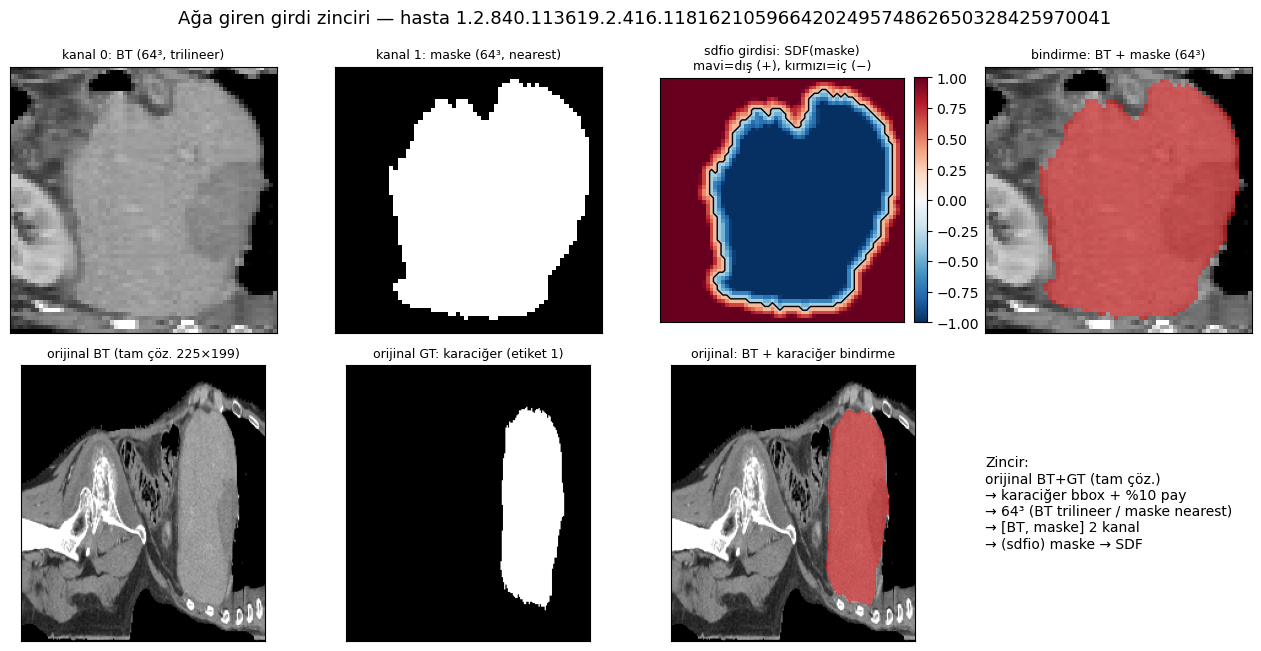

In [2]:
from data.raos_image_volume import RAOSImageVolumes
from data.raos_image import image_path_for, load_ct_volume, window_normalize, WINDOW_LO, WINDOW_HI
from data.raos_dataset import label_path_for
from quality.sdf_paper import batch_input_sdf, DELTA

SEED = 42
config = load_config(str(PROJECT_ROOT / 'configs' / 'vae3d_vq_sdf_io.yaml'))
config.setdefault('data', {})['data_source'] = 'precomputed'
set_seed(SEED)

# ağa giren 64³ kanallar (precomputed) — ilk test hastası
_ds = RAOSImageVolumes.from_config(config, split='test')
PIPE_IDX = 0
rec = _ds.samples[PIPE_IDX]
mask64 = np.asarray(_ds[PIPE_IDX]['mask'], dtype=bool)         # 64^3 maske kanalı
img64 = np.asarray(_ds[PIPE_IDX]['image'], dtype=np.float32)   # 64^3 BT kanalı
# sdfio'nun gördüğü: maske kanalının normalize SDF'si (kanal 1 dönüşümü)
sdf64 = batch_input_sdf(torch.from_numpy(mask64[None, None].astype('float32')), DELTA)[0, 0].numpy()

# orijinal tam-çözünürlük BT + ham GT (karaciğer = etiket 1)
raw_ct = load_ct_volume(image_path_for(_ds.root, rec))             # HU, tam çözünürlük
raw_ct_disp = window_normalize(raw_ct, WINDOW_LO, WINDOW_HI)       # görüntüleme için [0,1]
raw_lab = load_ct_volume(label_path_for(_ds.root, rec))
raw_liver = (np.rint(raw_lab).astype(int) == int(config['organs']['liver']))
# ham GT'de karaciğerin bulunduğu eksenel kesit (en çok karaciğer vokseli olan dilim)
zc_raw = int(raw_liver.sum(axis=(1, 2)).argmax())
zc64 = mask64.shape[0] // 2

print(f'hasta                : {rec["patient_id"]}  (split {rec["original_split"]})')
print(f'orijinal BT boyutu   : {raw_ct.shape}  (HU aralığı {raw_ct.min():.0f}..{raw_ct.max():.0f})')
print(f'ağa giren hacim      : {img64.shape}  (BT [0,1], maske ikili)')
print(f'SDF aralığı (kanal1) : [{sdf64.min():.2f}, {sdf64.max():.2f}]  (δ={DELTA})')

fig, axes = plt.subplots(2, 4, figsize=(13, 6.6))
# üst satır: ağa giren 64^3 gösterim
axes[0,0].imshow(img64[zc64], cmap='gray'); axes[0,0].set_title('kanal 0: BT (64³, trilineer)', fontsize=9)
axes[0,1].imshow(mask64[zc64], cmap='gray'); axes[0,1].set_title('kanal 1: maske (64³, nearest)', fontsize=9)
im = axes[0,2].imshow(sdf64[zc64], cmap='RdBu_r', vmin=-1, vmax=1)
axes[0,2].contour(sdf64[zc64], levels=[0.0], colors='k', linewidths=1.0)
axes[0,2].set_title('sdfio girdisi: SDF(maske)\nmavi=dış (+), kırmızı=iç (−)', fontsize=9)
fig.colorbar(im, ax=axes[0,2], fraction=0.046, pad=0.04)
axes[0,3].imshow(img64[zc64], cmap='gray')
axes[0,3].imshow(np.ma.masked_where(~mask64[zc64], mask64[zc64]), cmap='autumn', alpha=0.45)
axes[0,3].set_title('bindirme: BT + maske (64³)', fontsize=9)
# alt satır: orijinal tam çözünürlük
axes[1,0].imshow(raw_ct_disp[zc_raw], cmap='gray'); axes[1,0].set_title(f'orijinal BT (tam çöz. {raw_ct.shape[1]}×{raw_ct.shape[2]})', fontsize=9)
axes[1,1].imshow(raw_liver[zc_raw], cmap='gray'); axes[1,1].set_title('orijinal GT: karaciğer (etiket 1)', fontsize=9)
axes[1,2].imshow(raw_ct_disp[zc_raw], cmap='gray')
axes[1,2].imshow(np.ma.masked_where(~raw_liver[zc_raw], raw_liver[zc_raw]), cmap='autumn', alpha=0.45)
axes[1,2].set_title('orijinal: BT + karaciğer bindirme', fontsize=9)
axes[1,3].axis('off')
axes[1,3].text(0.0, 0.5,
    'Zincir:\norijinal BT+GT (tam çöz.)\n→ karaciğer bbox + %10 pay\n→ 64³ (BT trilineer / maske nearest)\n'
    '→ [BT, maske] 2 kanal\n→ (sdfio) maske → SDF',
    fontsize=10, va='center')
for ax in axes.ravel():
    if ax.images or ax.collections: ax.set_xticks([]); ax.set_yticks([])
fig.suptitle(f'Ağa giren girdi zinciri — hasta {rec["patient_id"]}', fontsize=13)
fig.tight_layout()
out = PROJECT_ROOT / 'outputs' / 'rapor_girdi_zinciri.png'
fig.savefig(out, dpi=150, bbox_inches='tight'); print('kaydedildi:', out); plt.show()

## 3. Üç girdi (bozulma) rejimi

Modeller, eğitim sırasında girdi maskesinin **nasıl bozulduğuna** göre üç rejimde eğitildi. Hedef
(target) her zaman temiz maskedir; yalnızca girdi değişir. Değerlendirme ise üç rejimde de **aynı
standart bozulma kümesiyle** yapılır (karşılaştırılabilirlik için), dolayısıyla rejimler arasındaki
tek fark eğitim verisinin bozulma dağılımıdır.

- **temiz-girdi** — girdi maskesi hiç bozulmaz (girdi = hedef). Model, görüntü kanalını kullanmadan
  maskeyi doğrudan kopyalayabilir; bu bir temel (baseline) çalışma noktasıdır.
- **karışık (mixed)** — hafif standart bozulmalar (`erode`, `dilate`, `remove_blob`,
  `boundary_noise`, `translate`, `add_false_positive`) **ile** ağır eksik-maske bozulmalarının
  (`heavy_erode`, `center_only`, `partial`) birleşimi. Hem küçük kenar/leke hatalarını hem de
  merkez-only / parça / ağır-erozyon gibi ağır tamamlama vakalarını kapsar.
- **saf-partial (partial)** — yalnızca ağır eksik-maske bozulmaları (`heavy_erode`, `center_only`,
  `partial`). Girdi ağır biçimde eksiktir; model maskeyi kopyalayamaz, eksik bölgeyi doldurmak için
  BT görüntüsünü okumak zorundadır.

Aşağıda her primitif **artan şiddette** (sev 0.2 → 1.0) bir temiz maske üzerinde gösterilir; her
hücrede orta eksenel kesit ve oluşan Dice yazar — düşük Dice = daha ağır bozulma. Renk kodu:
**beyaz** = kalan maske, **kırmızı** = silinen voksel, **yeşil** = eklenen (yanlış-pozitif) voksel.
Son üç satır (`heavy_erode`, `center_only`, `partial`) **ağır eksik-maske** vakalarıdır: şiddet
arttıkça maskenin büyük kısmı kaybolur (Dice ~0.5 ve altına iner) — tamamlama rejiminin asıl zor
senaryosu budur.

kaydedildi: C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality\outputs\rapor_bozulma_siddet_taramasi.png


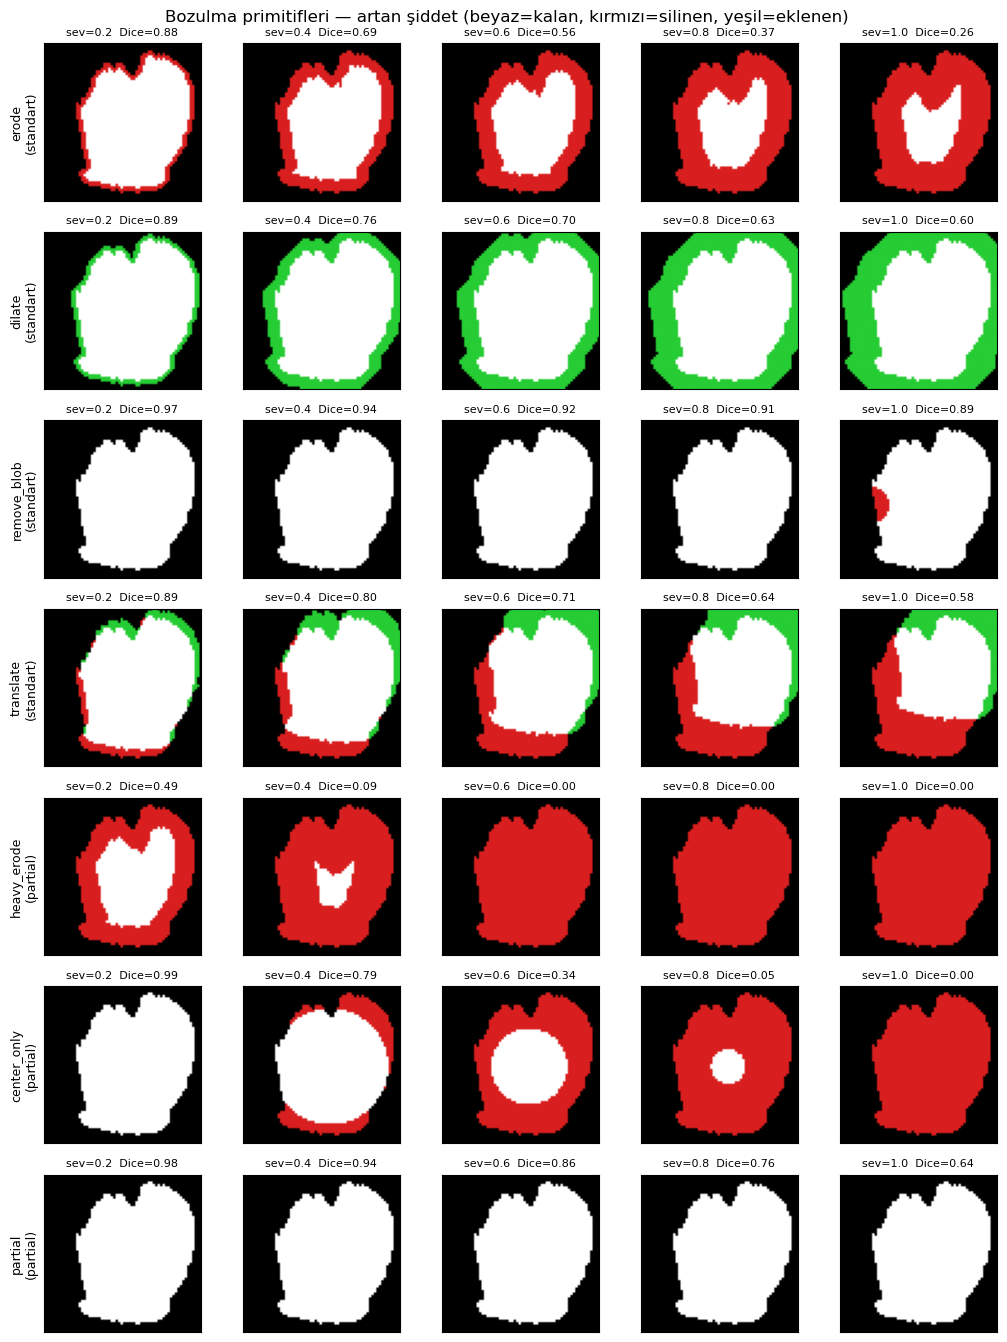

In [3]:
SEED = 42
config = load_config(str(PROJECT_ROOT / 'configs' / 'vae3d_vq_sdf_io.yaml'))
config.setdefault('data', {})['data_source'] = 'precomputed'
set_seed(SEED)

# tek bir temiz test maskesi (primitif görselleştirmesi için)
_clean_masks, _clean_images = evic.load_clean_image_volumes(config, 'test', None, SEED)
demo_mask = _clean_masks[0].astype(bool)
from data.degradations import dice as _dice

ALL_FNS = {**PRIMITIVES_3D, **PARTIAL_PRIMITIVES_3D}
prims = [('erode', 'standart'), ('dilate', 'standart'), ('remove_blob', 'standart'),
         ('translate', 'standart'), ('heavy_erode', 'partial'), ('center_only', 'partial'),
         ('partial', 'partial')]
severities = [0.2, 0.4, 0.6, 0.8, 1.0]
zc = demo_mask.shape[0] // 2
base2d = demo_mask[zc]

fig, axes = plt.subplots(len(prims), len(severities),
                         figsize=(2.1 * len(severities), 1.95 * len(prims)))
for ri, (name, tag) in enumerate(prims):
    fn = ALL_FNS[name]
    for ci, sev in enumerate(severities):
        out = np.asarray(fn(demo_mask, sev, np.random.default_rng(SEED))) > 0
        d = float(_dice(demo_mask, out))
        o2d = out[zc]
        rgb = np.zeros(base2d.shape + (3,))
        rgb[o2d] = [1.0, 1.0, 1.0]                 # kalan
        rgb[base2d & ~o2d] = [0.85, 0.12, 0.12]    # silinen
        rgb[o2d & ~base2d] = [0.15, 0.80, 0.20]    # eklenen
        ax = axes[ri, ci]
        ax.imshow(rgb); ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f'sev={sev:.1f}  Dice={d:.2f}', fontsize=8)
        if ci == 0:
            ax.set_ylabel(f'{name}\n({tag})', fontsize=9)
fig.suptitle('Bozulma primitifleri — artan şiddet (beyaz=kalan, kırmızı=silinen, yeşil=eklenen)',
             fontsize=12)
fig.tight_layout()
out = PROJECT_ROOT / 'outputs' / 'rapor_bozulma_siddet_taramasi.png'
fig.savefig(out, dpi=150, bbox_inches='tight'); print('kaydedildi:', out); plt.show()

## 4. Ortak değerlendirme kümesi (görüntü-farkında)

Test bölünmesindeki her temiz karaciğer için: standart bozulma primitifleri bu maskeler üzerinde
kalibre edilir, sonra her temiz maskeden `N_PER_MASK` adet bozuk varyant üretilir. **Görüntü hastaya
sabittir** — temiz ve bozuk tüm satırlar aynı hastanın temiz BT görüntüsünü taşır (tamamlama
kurulumu: maske bozulur, görüntü sabit kalır). Bütün görüntü-koşullu modeller tam olarak bu kümede
skorlanır.

In [4]:
N_PER_MASK = 5

clean_masks, clean_images = evic.load_clean_image_volumes(config, 'test', None, SEED)
degrader = ev3d.calibrate_degrader(config, clean_masks, SEED)
masks, images, true_dice, is_clean = evic.build_eval_set_imgcond(
    clean_masks, clean_images, degrader, N_PER_MASK, SEED)
is_clean = np.asarray(is_clean, dtype=bool)
deg = ~is_clean

print(f'hasta sayısı (temiz karaciğer) : {len(clean_masks)}')
print(f'değerlendirme kümesi           : {len(masks)} hacim  ({is_clean.sum()} temiz + {deg.sum()} bozuk)')
print(f'her hacmin şekli (3B, 64^3)    : {masks.shape[1:]}')
print(f'görüntü kanalı şekli           : {images.shape[1:]}  aralık [{images.min():.2f}, {images.max():.2f}]')
print(f'gerçek Dice aralığı            : [{true_dice.min():.3f}, {true_dice.max():.3f}]')
print(f'kalibre bozulma aralıkları     :')
for k, v in (degrader.type_ranges or {}).items():
    print(f'    {k:18s} Dice ∈ [{v[0]:.2f}, {v[1]:.2f}]')

hasta sayısı (temiz karaciğer) : 47
değerlendirme kümesi           : 282 hacim  (47 temiz + 235 bozuk)
her hacmin şekli (3B, 64^3)    : (64, 64, 64)
görüntü kanalı şekli           : (64, 64, 64)  aralık [0.00, 1.00]
gerçek Dice aralığı            : [0.389, 1.000]
kalibre bozulma aralıkları     :
    erode              Dice ∈ [0.00, 0.94]
    dilate             Dice ∈ [0.42, 0.94]
    remove_blob        Dice ∈ [0.80, 1.00]
    add_false_positive Dice ∈ [0.86, 0.99]
    boundary_noise     Dice ∈ [0.49, 1.00]
    translate          Dice ∈ [0.19, 0.96]


## 5. Model kayıt defteri

Dokuz görüntü-koşullu deney: üç rejim × (nicemleyici, baş) kombinasyonları. Her satır bir
checkpoint'e, bir çıktı başına (binary/sdfio), bir nicemleyiciye (vq/simvq) ve bir girdi rejimine
karşılık gelir. Checkpoint yolları açıkça yazılıdır; defter bu yollardan modelleri canlı yükleyip
yeniden skorlar.

In [5]:
CKPT = PROJECT_ROOT / 'outputs' / 'checkpoints'

# (etiket, tag, head, quantizer, rejim, girdi)
IMG_REGISTRY = [
    ('E2',  'e2',  'binary', 'simvq', 'temiz-girdi',  'temiz'),
    ('E4',  'e4',  'sdfio',  'vq',    'temiz-girdi',  'temiz'),
    ('E5',  'e5',  'sdfio',  'simvq', 'temiz-girdi',  'temiz'),
    ('E3',  'e3',  'binary', 'simvq', 'karışık',      'bozuk'),
    ('E6',  'e6',  'sdfio',  'vq',    'karışık',      'bozuk'),
    ('E7',  'e7',  'sdfio',  'simvq', 'karışık',      'bozuk'),
    ('E3p', 'e3p', 'binary', 'simvq', 'saf-partial',  'bozuk'),
    ('E6p', 'e6p', 'sdfio',  'vq',    'saf-partial',  'bozuk'),
    ('E7p', 'e7p', 'sdfio',  'simvq', 'saf-partial',  'bozuk'),
]
for lbl, tag, *_ in IMG_REGISTRY:
    p = CKPT / f'vae3d_{tag}_best.pt'
    print(('VAR ' if p.exists() else 'YOK ') + f'{lbl:4s} <- {p.name}')

VAR E2   <- vae3d_e2_best.pt
VAR E4   <- vae3d_e4_best.pt
VAR E5   <- vae3d_e5_best.pt
VAR E3   <- vae3d_e3_best.pt
VAR E6   <- vae3d_e6_best.pt
VAR E7   <- vae3d_e7_best.pt
VAR E3p  <- vae3d_e3p_best.pt
VAR E6p  <- vae3d_e6p_best.pt
VAR E7p  <- vae3d_e7p_best.pt


## 6. Görüntü-koşullu modelleri canlı skorla

Her model checkpoint'ten yüklenir ve ortak değerlendirme kümesinde tüm skorları (`recon_dice`,
`recon_l1`, `topology`, `quant_error` ve sdfio başı için `sdf_l1`) hesaplanır. `recon_dice`, 1-kanal
rekonstrüksiyonu girdi maske kanalıyla karşılaştırır. SimVQ'da `quant_error` efektif codebook `C·W`
üzerinden ölçülür.

In [6]:
img_results = {}   # etiket -> dict(scores, summary, head, quantizer, regime, input, epoch)

for lbl, tag, head, quant, regime, inp in IMG_REGISTRY:
    path = CKPT / f'vae3d_{tag}_best.pt'
    if not path.exists():
        print('YOK, atlanıyor:', lbl); continue
    model = evic.load_imgcond_model(path, head, quant, device)
    fns, dirs = evic.build_score_registry(head, quant)
    scores = evic.score_masks_imgcond(model, masks, images, fns, device)
    summary = evic.summarise_imgcond(scores, true_dice, dirs)
    ckpt = torch.load(path, map_location='cpu', weights_only=False)
    img_results[lbl] = dict(scores=scores, summary=summary, head=head, quantizer=quant,
                            regime=regime, input=inp, epoch=ckpt.get('epoch'),
                            model=model, path=str(path))
    rd = summary['recon_dice']['global']['spearman']
    print(f'{lbl:4s} [{regime:12s} {head:6s}/{quant:5s}]  recon_dice ρ = {rd:.3f}  (epoch {ckpt.get("epoch")})')

E2   [temiz-girdi  binary/simvq]  recon_dice ρ = 0.819  (epoch 61)
E4   [temiz-girdi  sdfio /vq   ]  recon_dice ρ = 0.821  (epoch 95)
E5   [temiz-girdi  sdfio /simvq]  recon_dice ρ = 0.821  (epoch 26)
E3   [karışık      binary/simvq]  recon_dice ρ = 0.975  (epoch 75)
E6   [karışık      sdfio /vq   ]  recon_dice ρ = 0.977  (epoch 93)
E7   [karışık      sdfio /simvq]  recon_dice ρ = 0.969  (epoch 56)
E3p  [saf-partial  binary/simvq]  recon_dice ρ = 0.967  (epoch 66)
E6p  [saf-partial  sdfio /vq   ]  recon_dice ρ = 0.946  (epoch 93)
E7p  [saf-partial  sdfio /simvq]  recon_dice ρ = 0.940  (epoch 43)


## 7. Şekil-tavanı: yalnızca maske kullanan önceki yöntemler

Görüntü kanalı eklenmeden önceki yöntemler aynı 282-hacimlik protokolde değerlendirilmişti. Bu
sonuçlar, görüntü-koşullu modellerin kırmaya çalıştığı **tavanı** oluşturur. `recon_dice` ρ'ları
kayıtlı JSON dosyalarından okunur (aynı seed, aynı bozulmalar).

In [7]:
CEILING_FILES = [
    ('VQ (maske)',          'correlation_results_vq.json'),
    ('SimVQ (maske)',       'correlation_results_simvq_simvq.json'),
    ('SDF-io+VQ (maske)',   'correlation_results_sdfio_sdfio.json'),
    ('E1: SDF-io+SimVQ (maske)', 'correlation_results_simvq_sdfio_simvq_sdfio.json'),
]
ceiling = {}
for lbl, fname in CEILING_FILES:
    fp = PROJECT_ROOT / 'outputs' / fname
    if not fp.exists():
        print('YOK:', fname); continue
    d = json.load(open(fp))
    rd = d['scores']['recon_dice']
    ceiling[lbl] = dict(global_rho=rd['global']['spearman'], bands=rd['bands'],
                        n=d.get('n_total'))
    print(f'{lbl:28s} recon_dice ρ = {rd["global"]["spearman"]:.3f}')

VQ (maske)                   recon_dice ρ = 0.862
SimVQ (maske)                recon_dice ρ = 0.843
SDF-io+VQ (maske)            recon_dice ρ = 0.832
E1: SDF-io+SimVQ (maske)     recon_dice ρ = 0.829


## 8. Özet tablo — girdi, Dice, global ρ

Her deney için: girdi rejimi ve temiz/bozuk oluşu, nicemleyici ve baş, temiz ve bozuk maskeler
üzerinde ortalama rekonstrüksiyon Dice'ı, `recon_dice`'ın global Spearman ρ'su ve (varsa)
`quant_error` ρ'su. Alt blokta maske-only tavan referans olarak verilir.

In [8]:
rows = []
for lbl, tag, head, quant, regime, inp in IMG_REGISTRY:
    if lbl not in img_results: continue
    r = img_results[lbl]
    rd = r['scores']['recon_dice']
    qe = correlation(r['scores']['quant_error'], true_dice)['spearman'] if 'quant_error' in r['scores'] else None
    rows.append({
        'deney': lbl, 'rejim': regime, 'girdi': inp, 'baş': head, 'quant': quant,
        'recon Dice (temiz)': round(float(rd[is_clean].mean()), 3),
        'recon Dice (bozuk)': round(float(rd[deg].mean()), 3),
        'ρ recon_dice': round(float(r['summary']['recon_dice']['global']['spearman']), 3),
        'ρ quant_error': None if qe is None else round(float(qe), 3),
    })
for lbl, info in ceiling.items():
    rows.append({'deney': lbl, 'rejim': 'maske-only (tavan)', 'girdi': 'bozuk', 'baş': '-', 'quant': '-',
                 'recon Dice (temiz)': None, 'recon Dice (bozuk)': None,
                 'ρ recon_dice': round(float(info['global_rho']), 3), 'ρ quant_error': None})

try:
    import pandas as pd
    summary_df = pd.DataFrame(rows)
    display(summary_df)
except Exception:
    for row in rows: print(row)

,deney,rejim,girdi,baş,quant,recon Dice (temiz),recon Dice (bozuk),ρ recon_dice,ρ quant_error
0,E2,temiz-girdi,temiz,binary,simvq,0.922,0.865,0.819,-0.234
1,E4,temiz-girdi,temiz,sdfio,vq,0.922,0.857,0.821,-0.453
2,E5,temiz-girdi,temiz,sdfio,simvq,0.903,0.833,0.821,-0.366
3,E3,karışık,bozuk,binary,simvq,0.907,0.688,0.975,0.165
4,E6,karışık,bozuk,sdfio,vq,0.908,0.691,0.977,0.365
5,E7,karışık,bozuk,sdfio,simvq,0.896,0.683,0.969,0.216
6,E3p,saf-partial,bozuk,binary,simvq,0.910,0.713,0.967,0.099
7,E6p,saf-partial,bozuk,sdfio,vq,0.910,0.731,0.946,0.215
8,E7p,saf-partial,bozuk,sdfio,simvq,0.898,0.723,0.940,0.019
9,VQ (maske),maske-only (tavan),bozuk,-,-,NaN,NaN,0.862,NaN


## 9. Bant-içi (within-band) korelasyon — ayrıntılı

**Global ρ neden tek başına yanıltıcı olabilir?** Değerlendirme kümesindeki 282 nokta yalnızca 47
hastadan gelir (her hasta için 1 temiz + 5 bozuk varyant). Global Spearman ρ, hem *hastalar-arası*
(farklı hastaların farklı kalite seviyeleri) hem *hasta-içi* değişkenliği birlikte kullanır.
Hastalar-arası bileşen "ayırt etmesi kolay" olduğundan global ρ'yu şişirir; ayrıca noktalar bağımsız
olmadığından (aynı hasta 6 kez) raporlanan p-değerleri aşırı iyimserdir.

**Bant-içi ρ nedir?** Gerçek Dice ekseni dar bantlara bölünür
(DICE_BANDS: [0.4–0.55], [0.55–0.7], [0.7–0.85], [0.85–1.0]) ve Spearman ρ **her bandın içinde**
ayrı hesaplanır. Soru şuna döner: *birbirine yakın kalitedeki maskeleri bile skor doğru
sıralayabiliyor mu?* Bu, kolay hastalar-arası sinyali eler ve skorun gerçek ayırt etme gücünü verir.
Dürüst değerlendirme sayısı budur.

Aşağıda her deney için bant-başına ρ tablosu ve çubuk grafik gösterilir.

In [9]:
def band_row(summary_or_bands):
    bands = summary_or_bands['recon_dice']['bands'] if 'recon_dice' in summary_or_bands else summary_or_bands
    return {f'[{b["band_lo"]:.2f}-{b["band_hi"]:.2f}] (n={b["n"]})': round(float(b['spearman']), 2) for b in bands}

band_rows = []
for lbl, tag, head, quant, regime, inp in IMG_REGISTRY:
    if lbl not in img_results: continue
    row = {'deney': lbl, 'rejim': regime, 'global': round(float(img_results[lbl]['summary']['recon_dice']['global']['spearman']), 2)}
    row.update(band_row(img_results[lbl]['summary']))
    band_rows.append(row)
for lbl, info in ceiling.items():
    row = {'deney': lbl, 'rejim': 'maske-only', 'global': round(float(info['global_rho']), 2)}
    row.update(band_row(info['bands']))
    band_rows.append(row)

try:
    import pandas as pd
    band_df = pd.DataFrame(band_rows)
    display(band_df)
except Exception:
    for row in band_rows: print(row)

,deney,rejim,global,[0.40-0.55] (n=59),[0.55-0.70] (n=56),[0.70-0.85] (n=58),[0.85-1.00] (n=108)
0,E2,temiz-girdi,0.82,0.18,0.43,0.16,0.38
1,E4,temiz-girdi,0.82,0.05,0.46,0.25,0.44
2,E5,temiz-girdi,0.82,0.31,0.20,0.11,0.39
3,E3,karışık,0.98,0.84,0.91,0.59,0.74
4,E6,karışık,0.98,0.75,0.90,0.67,0.77
5,E7,karışık,0.97,0.82,0.86,0.62,0.69
6,E3p,saf-partial,0.97,0.65,0.80,0.46,0.72
7,E6p,saf-partial,0.95,0.48,0.61,0.42,0.65
8,E7p,saf-partial,0.94,0.46,0.58,0.25,0.60
9,VQ (maske),maske-only,0.86,0.01,0.50,0.34,0.45


kaydedildi: C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality\outputs\rapor_bant_ici_rho.png


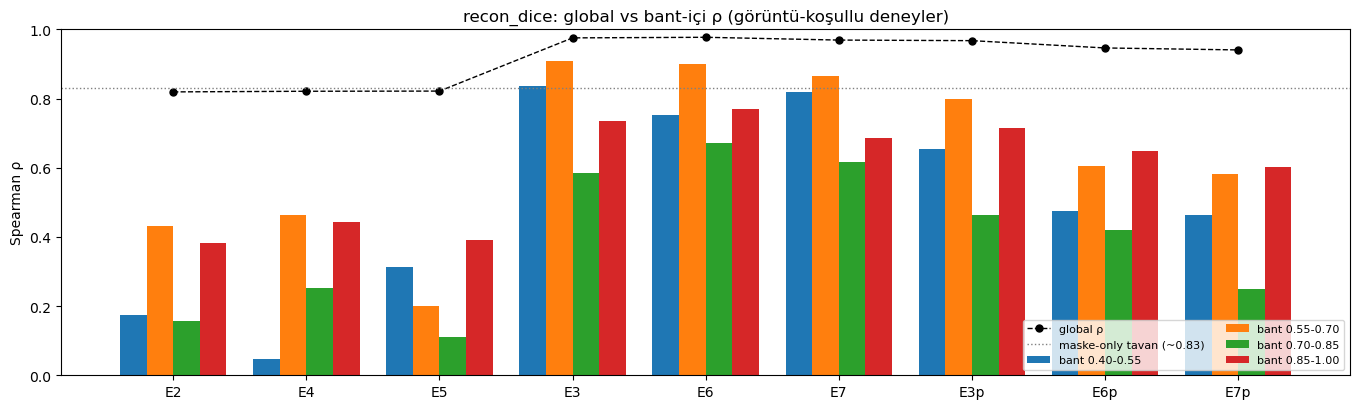

In [10]:
# bant-içi ρ çubuk grafiği (sadece görüntü-koşullu deneyler)
labels = [l for l, *_ in IMG_REGISTRY if l in img_results]
band_names = [f'{b["band_lo"]:.2f}-{b["band_hi"]:.2f}' for b in img_results[labels[0]]['summary']['recon_dice']['bands']]
nb = len(band_names)
x = np.arange(len(labels)); w = 0.8 / nb
fig, ax = plt.subplots(figsize=(1.3 * len(labels) + 2, 4.2))
for j, bn in enumerate(band_names):
    vals = [img_results[l]['summary']['recon_dice']['bands'][j]['spearman'] for l in labels]
    ax.bar(x + j * w, vals, w, label=f'bant {bn}')
glob = [img_results[l]['summary']['recon_dice']['global']['spearman'] for l in labels]
ax.plot(x + 0.4 - w/2, glob, 'ko--', lw=1, ms=5, label='global ρ')
ax.set_xticks(x + 0.4 - w/2); ax.set_xticklabels(labels)
ax.set_ylabel('Spearman ρ'); ax.set_ylim(0, 1.0)
ax.axhline(0.83, color='grey', ls=':', lw=1, label='maske-only tavan (~0.83)')
ax.set_title('recon_dice: global vs bant-içi ρ (görüntü-koşullu deneyler)')
ax.legend(fontsize=8, ncol=2, loc='lower right')
fig.tight_layout()
out = PROJECT_ROOT / 'outputs' / 'rapor_bant_ici_rho.png'
fig.savefig(out, dpi=150, bbox_inches='tight'); print('kaydedildi:', out); plt.show()

## 10. Scatter korelasyon grafikleri

Her deneyin `recon_dice` skoru gerçek Dice'a karşı çizilir. Temiz (Dice=1.0) ve bozuk maskeler ayrı
renklidir; dikey kesik çizgiler bant sınırlarıdır; başlıkta global ρ yazar. Temiz-girdi deneyleri
(E2/E4/E5) tavana yakın, düz bir bulut verir; bozuk-girdi (tamamlama) deneyleri belirgin eğim gösterir.

kaydedildi: C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality\outputs\rapor_scatter_hepsi.png


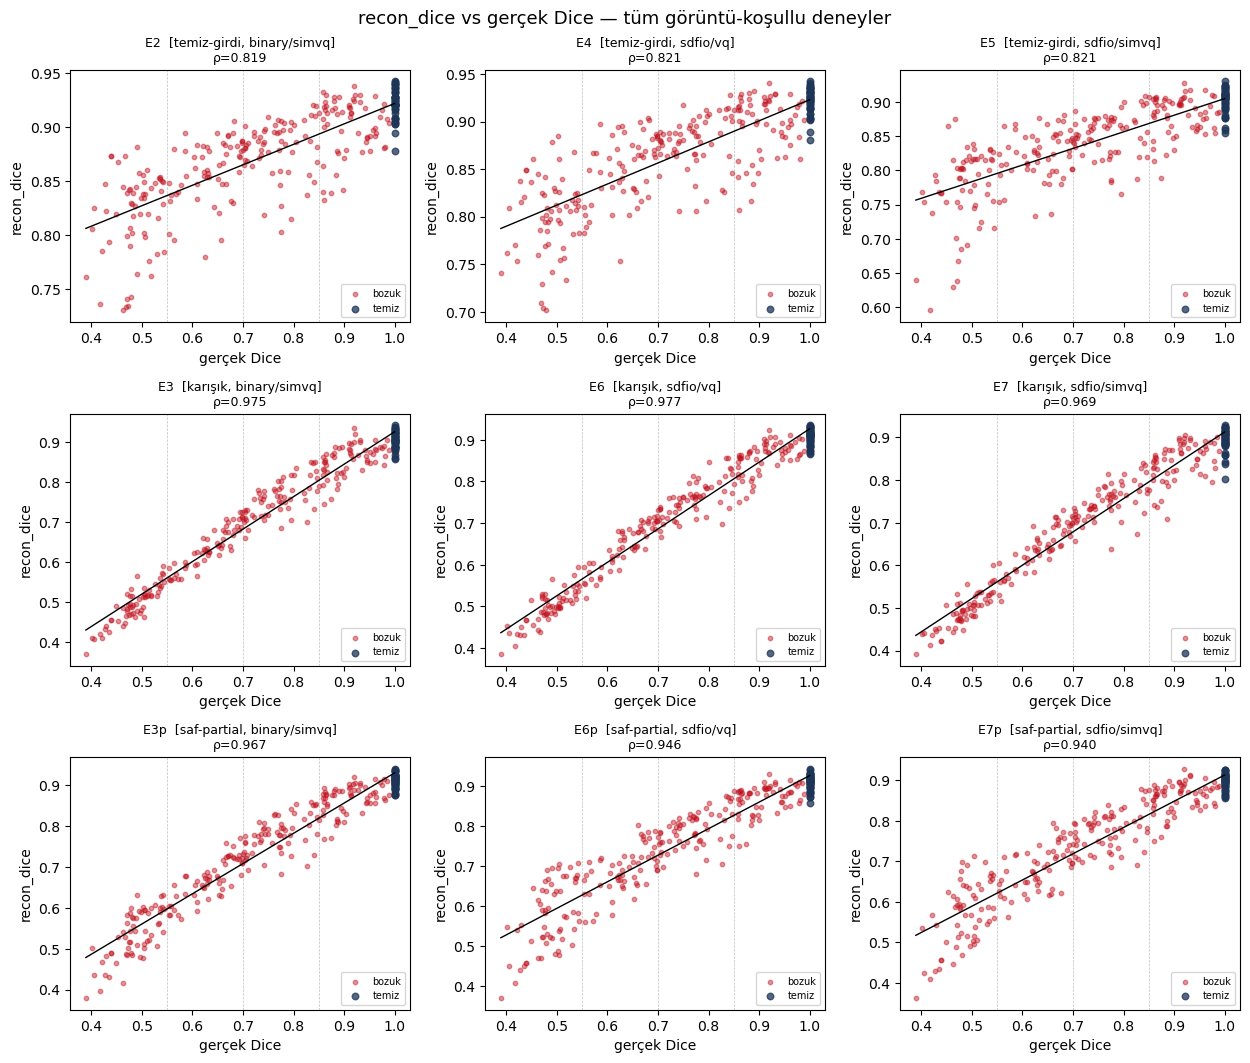

In [11]:
labels = [l for l, *_ in IMG_REGISTRY if l in img_results]
ncol = 3
nrow = int(np.ceil(len(labels) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4.2 * ncol, 3.6 * nrow))
axes = np.atleast_1d(axes).ravel()
for ax, lbl in zip(axes, labels):
    r = img_results[lbl]
    s = r['scores']['recon_dice']
    rho = r['summary']['recon_dice']['global']['spearman']
    ax.scatter(true_dice[deg], s[deg], s=10, alpha=0.45, c='#c1121f', label='bozuk')
    ax.scatter(true_dice[is_clean], s[is_clean], s=22, alpha=0.75, c='#1d3557', label='temiz')
    for _, hi in DICE_BANDS[:-1]:
        ax.axvline(hi, color='grey', lw=0.5, ls='--', alpha=0.5)
    order = np.argsort(true_dice); coef = np.polyfit(true_dice, s, 1)
    ax.plot(true_dice[order], np.polyval(coef, true_dice[order]), 'k-', lw=1.0)
    ax.set_title(f'{lbl}  [{r["regime"]}, {r["head"]}/{r["quantizer"]}]\nρ={rho:.3f}', fontsize=9)
    ax.set_xlabel('gerçek Dice'); ax.set_ylabel('recon_dice'); ax.legend(fontsize=7, loc='lower right')
for ax in axes[len(labels):]:
    ax.axis('off')
fig.suptitle('recon_dice vs gerçek Dice — tüm görüntü-koşullu deneyler', fontsize=13)
fig.tight_layout()
out = PROJECT_ROOT / 'outputs' / 'rapor_scatter_hepsi.png'
fig.savefig(out, dpi=150, bbox_inches='tight'); print('kaydedildi:', out); plt.show()

## 11. Görsel paneller — her deney, hafif → ağır bozulmada

Bütün görüntü-koşullu deneyler (E2–E7 + saf-partial) **aynı hastada** ve **aynı üç bozuk girdide**
gösterilir: hafif, orta ve **ağır** eksik-maske. Her deney için satırlar bu üç şiddet; sütunlar:

**BT görüntü | temiz (GT) | bozuk girdi | model ham çıktısı | ikili tamamlama**

- **Ham çıktı** modelin gerçekte ürettiği süreklidir — ikili değil. *sdfio* başında bu bir
  **işaretli-mesafe alanıdır** (RdBu: mavi=dış +, kırmızı=iç −, siyah çizgi = sıfır yüzeyi =
  maske sınırı); *binary* başında bir **olasılık haritasıdır** (magma, [0,1]). İkili tamamlama
  bu sürekli alanın eşiklenmesidir (sdfio: `SDF < 0 → içeri`; binary: `olasılık > 0.5`). "sdfio
  çıktısı neden ikili görünüyor?" sorusunun yanıtı budur: ağ sürekli SDF üretir, ikili yalnızca
  son eşikleme adımıdır.
- Başlıklarda Dice(bozuk girdi, GT) ve Dice(tamamlama, GT) yazar — model BT'yi kullanarak eksik
  bölgeyi ne kadar geri getirmiş onu gösterir. Temiz-girdi deneylerinde (E2/E4/E5) model maskeyi
  kopyalamaya eğilimli olduğundan ağır bozulmada tamamlama zayıf kalır; tamamlama rejimlerinde
  (karışık / saf-partial) ağır bozulmada bile şekil büyük ölçüde geri gelir.

panel bozuk girdiler (seviye, primitif, Dice): [('hafif/partial', 0.86), ('orta/erode', 0.62), ('ağır/center_only', 0.34)]
kaydedildi: C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality\outputs\rapor_panel_E2.png


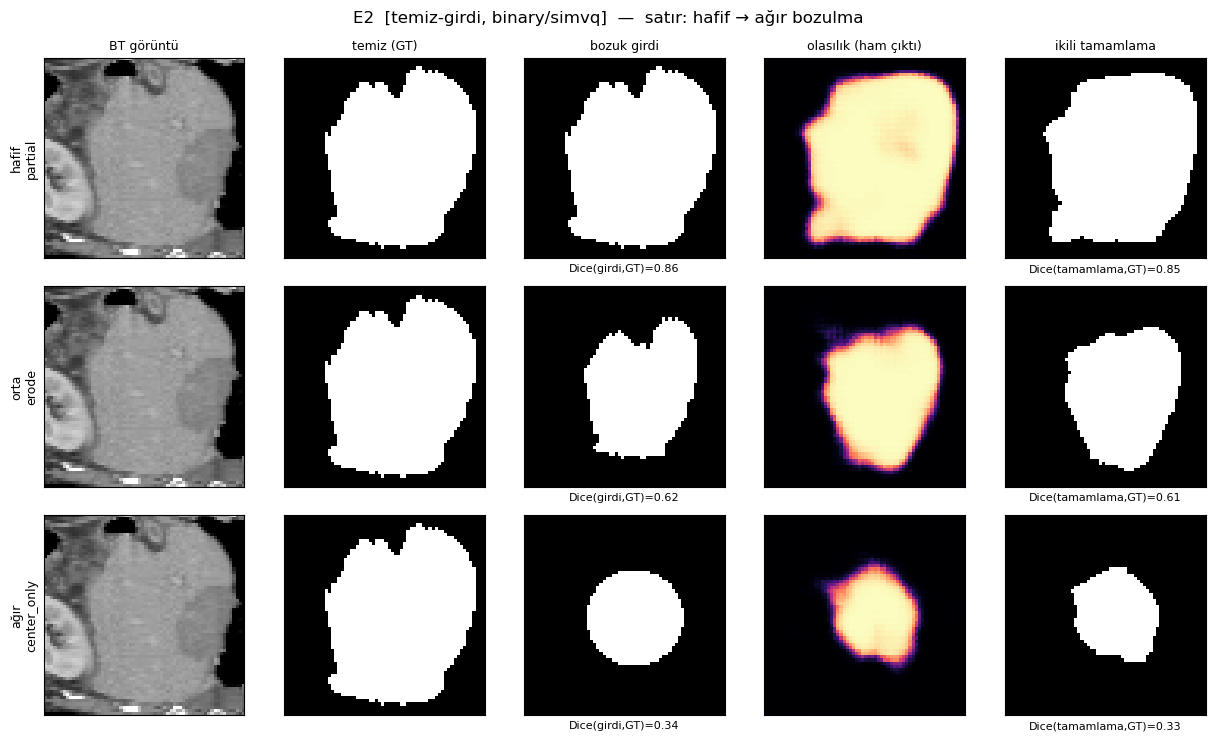

kaydedildi: C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality\outputs\rapor_panel_E4.png


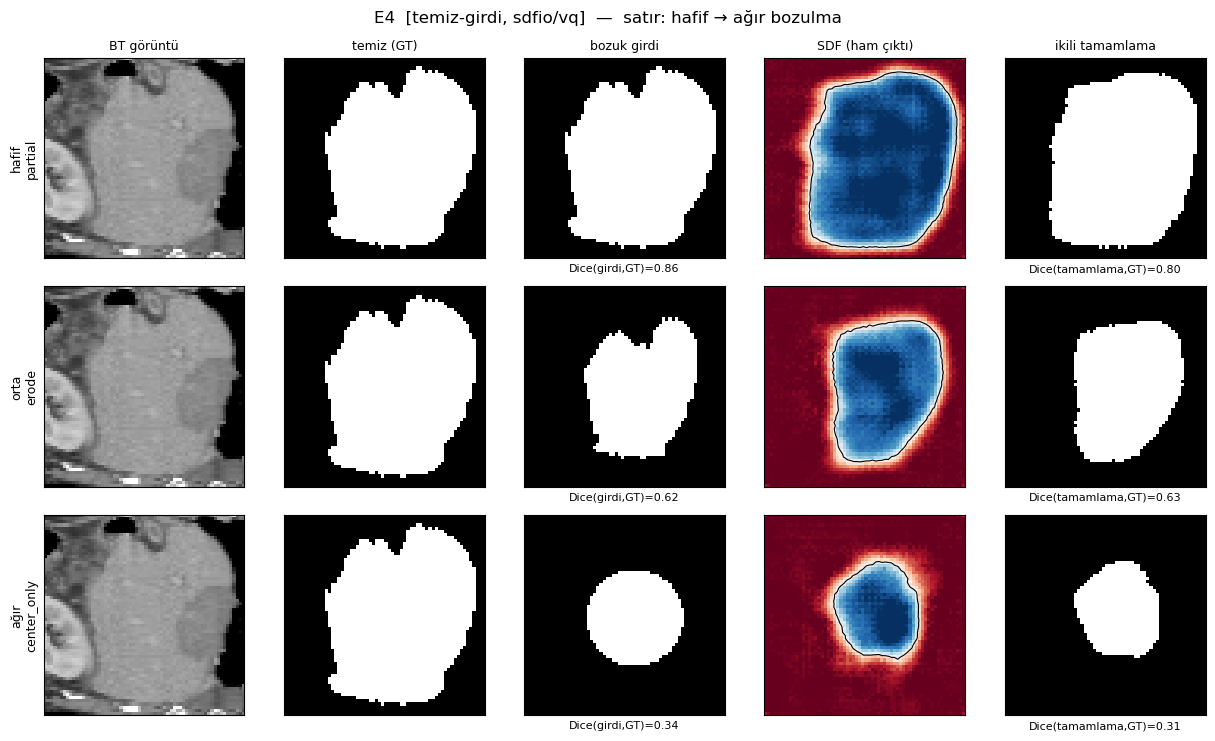

kaydedildi: C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality\outputs\rapor_panel_E5.png


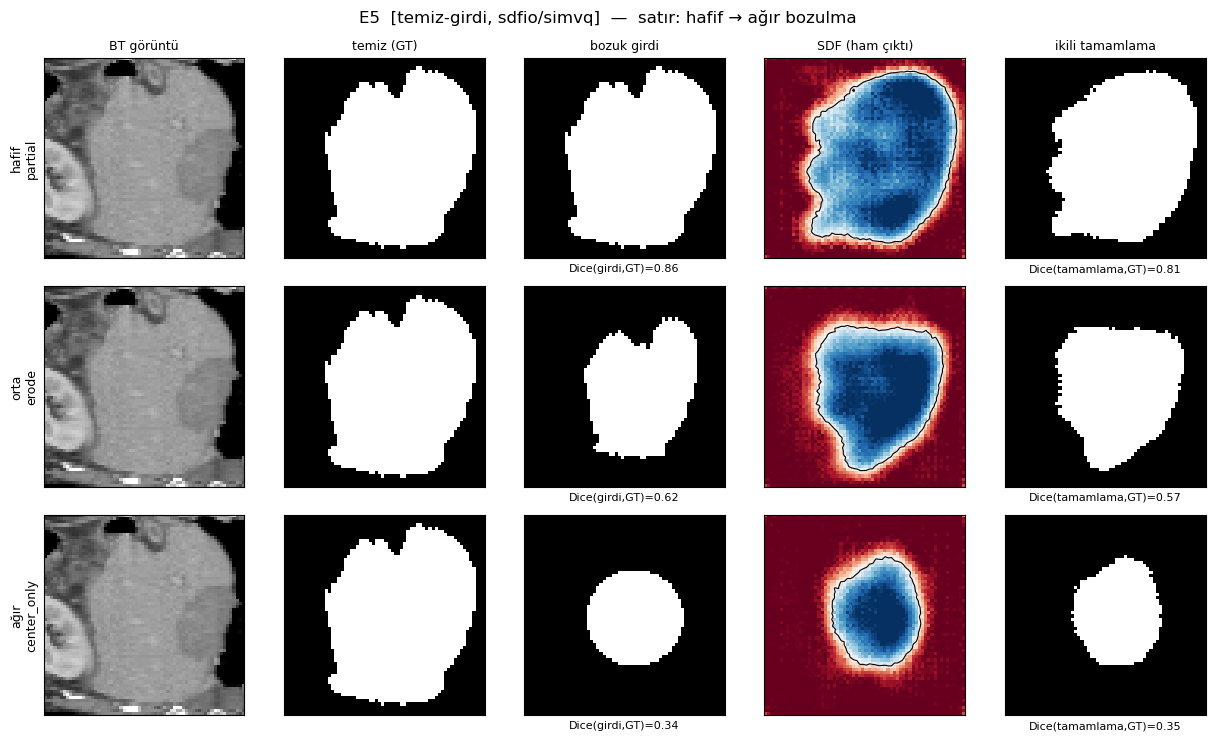

kaydedildi: C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality\outputs\rapor_panel_E3.png


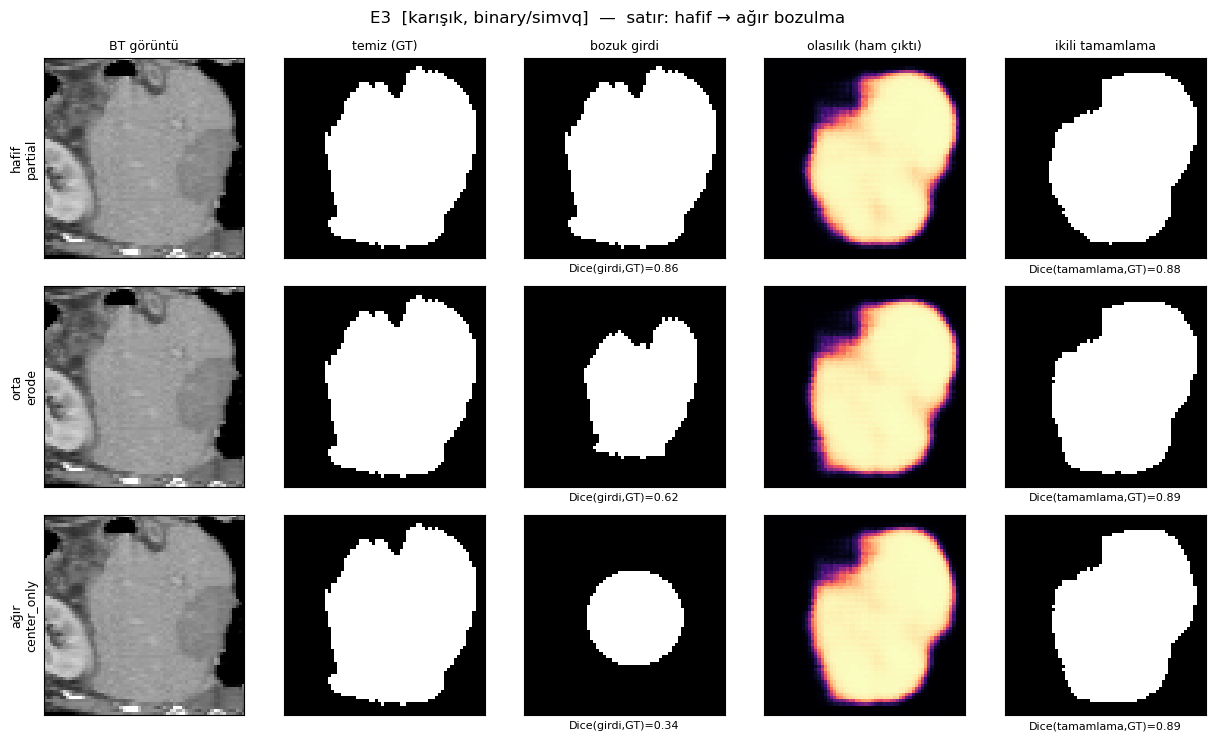

kaydedildi: C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality\outputs\rapor_panel_E6.png


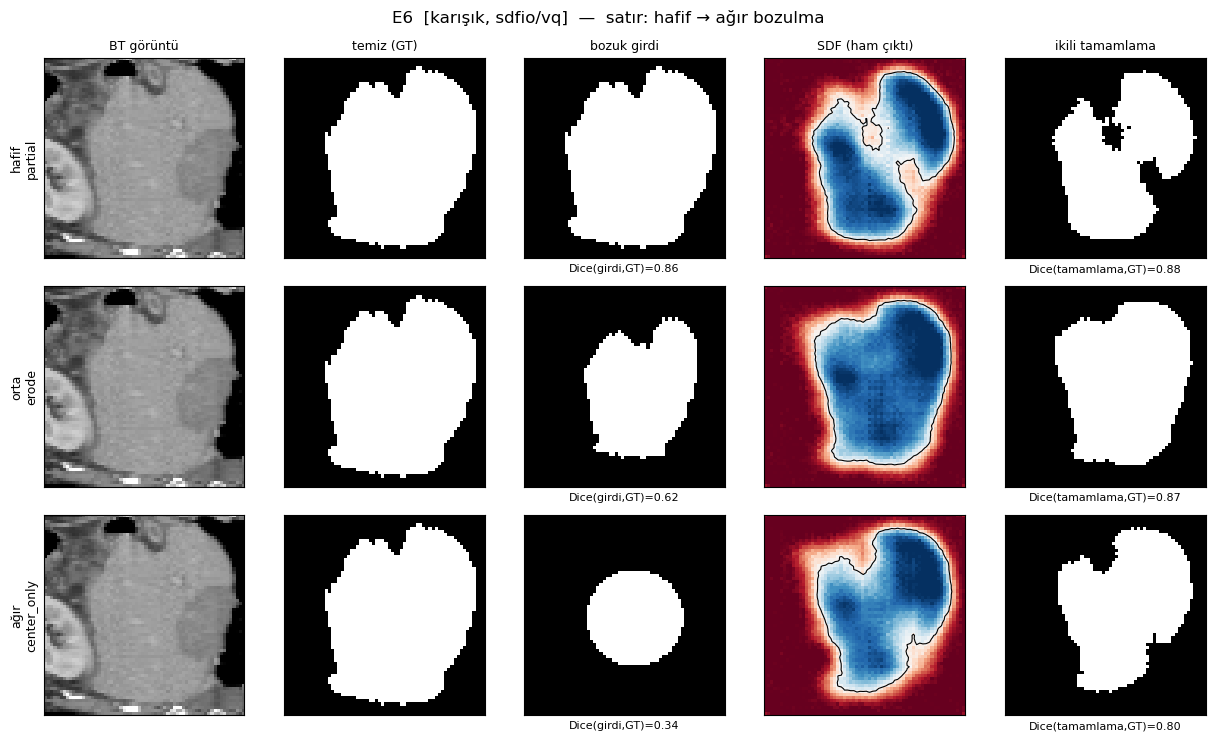

kaydedildi: C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality\outputs\rapor_panel_E7.png


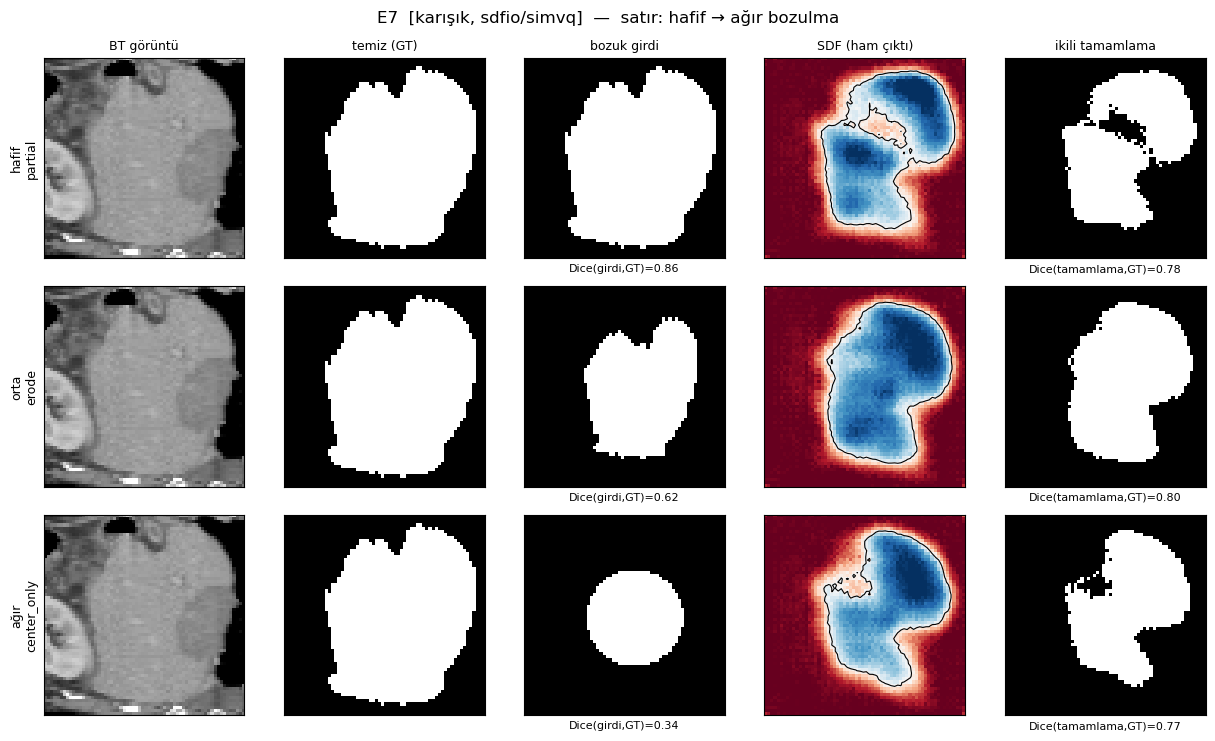

kaydedildi: C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality\outputs\rapor_panel_E3p.png


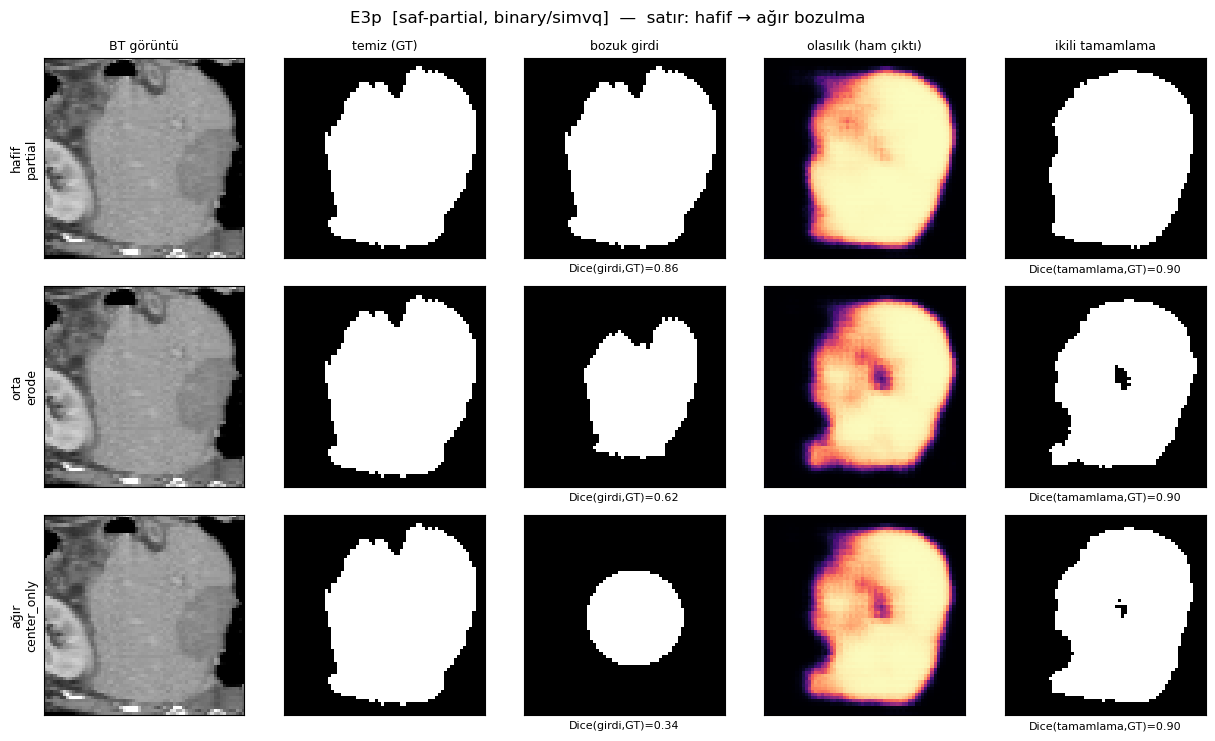

kaydedildi: C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality\outputs\rapor_panel_E6p.png


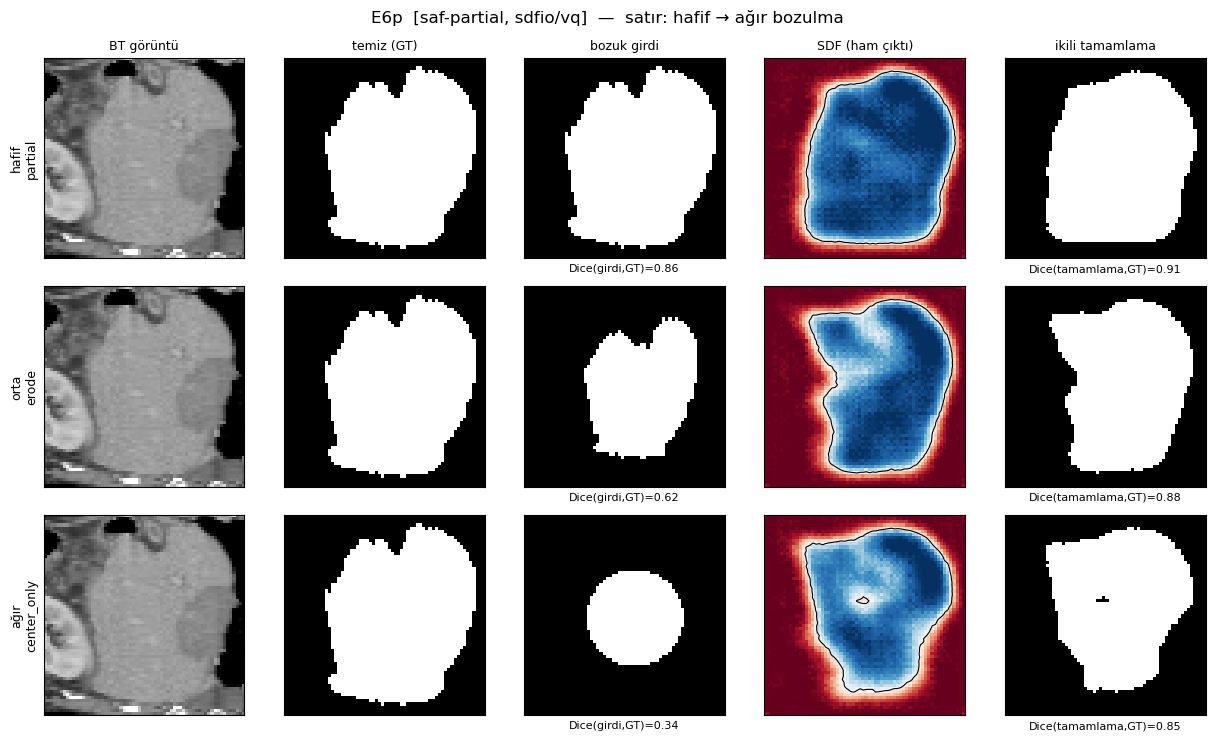

kaydedildi: C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality\outputs\rapor_panel_E7p.png


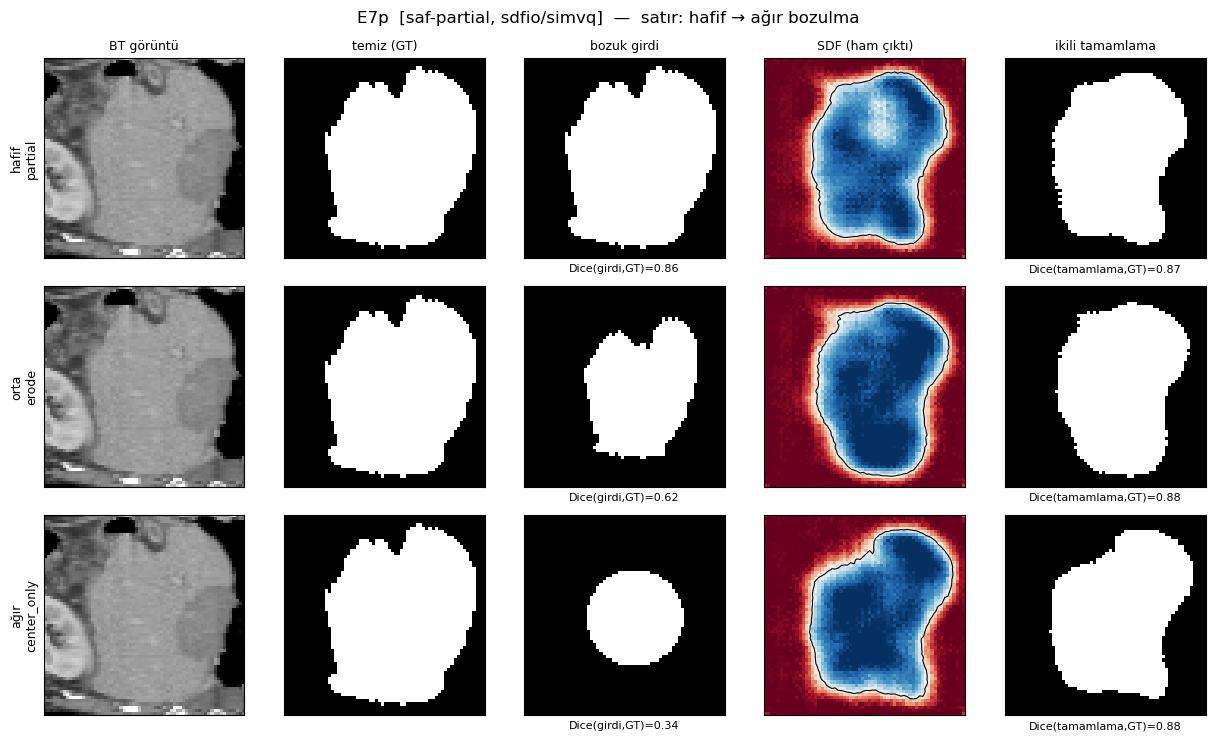

In [12]:
from data.degradations import dice as _dc

# aynı hasta + aynı üç bozuk girdi (hafif / orta / ağır) — tüm deneyler bunlarda karşılaştırılır.
# Hedef Dice ~[0.85, 0.65, 0.45] olacak şekilde aday (primitif, şiddet) havuzundan en yakınları seçilir,
# böylece seviyeler tek-yönlü sıralı ve ağır vaka gerçekten ağır (ama boş değil) olur.
PANEL_IDX = 0
panel_gt = clean_masks[PANEL_IDX].astype(bool)
panel_img = clean_images[PANEL_IDX]
_cands = []
for name, sev in [('erode', 0.15), ('erode', 0.3), ('erode', 0.5), ('dilate', 0.4),
                  ('partial', 0.4), ('partial', 0.6), ('heavy_erode', 0.3),
                  ('center_only', 0.4), ('center_only', 0.6), ('center_only', 0.75)]:
    b = np.asarray(ALL_FNS[name](panel_gt, sev, np.random.default_rng(SEED))) > 0
    if 0 < int(b.sum()) < panel_gt.size:
        _cands.append((b, float(_dc(panel_gt, b)), name))
panel_broken = []
_used = []
for target, lvl in [(0.85, 'hafif'), (0.65, 'orta'), (0.45, 'ağır')]:
    best_k = min((k for k in range(len(_cands)) if k not in _used),
                 key=lambda k: abs(_cands[k][1] - target))
    _used.append(best_k)
    b, d, name = _cands[best_k]
    panel_broken.append((b, d, f'{lvl}\n{name}'))
zc = panel_gt.shape[0] // 2
print('panel bozuk girdiler (seviye, primitif, Dice):',
      [(lvl.replace(chr(10), '/'), round(d, 2)) for _, d, lvl in panel_broken])

@torch.no_grad()
def complete(model, img, mask):
    x = torch.from_numpy(np.stack([img, mask.astype('float32')])[None]).float().to(device)
    return (model.reconstruct(x)[0, 0].cpu().numpy() > 0.5)

@torch.no_grad()
def raw_field(model, img, mask, head):
    x = torch.from_numpy(np.stack([img, mask.astype('float32')])[None]).float().to(device)
    if head == 'sdfio':
        f = model.predict_sdf(x)[0, 0].cpu().numpy()
        return f, dict(cmap='RdBu_r', vmin=-1, vmax=1), 'SDF (ham çıktı)', True
    f = model.reconstruct(x)[0, 0].cpu().numpy()
    return f, dict(cmap='magma', vmin=0, vmax=1), 'olasılık (ham çıktı)', False

def full_panel(lbl):
    r = img_results[lbl]; model = r['model']; head = r['head']
    cols = ['BT görüntü', 'temiz (GT)', 'bozuk girdi', 'ham çıktı', 'ikili tamamlama']
    fig, axes = plt.subplots(len(panel_broken), len(cols),
                             figsize=(2.5 * len(cols), 2.5 * len(panel_broken)))
    for ri, (brk, d_in, lvl) in enumerate(panel_broken):
        field, style, raw_title, is_sdf = raw_field(model, panel_img, brk, head)
        comp = complete(model, panel_img, brk)
        d_comp = float(_dc(panel_gt, comp))
        axes[ri, 0].imshow(panel_img[zc], cmap='gray')
        axes[ri, 1].imshow(panel_gt[zc], cmap='gray')
        axes[ri, 2].imshow(brk[zc], cmap='gray')
        im = axes[ri, 3].imshow(field[zc], **style)
        if is_sdf:
            axes[ri, 3].contour(field[zc], levels=[0.0], colors='k', linewidths=0.8)
        axes[ri, 4].imshow(comp[zc], cmap='gray')
        for ci in range(len(cols)):
            axes[ri, ci].set_xticks([]); axes[ri, ci].set_yticks([])
            if ri == 0:
                axes[ri, ci].set_title(raw_title if ci == 3 else cols[ci], fontsize=9)
        axes[ri, 0].set_ylabel(lvl, fontsize=9)
        axes[ri, 2].set_xlabel(f'Dice(girdi,GT)={d_in:.2f}', fontsize=8)
        axes[ri, 4].set_xlabel(f'Dice(tamamlama,GT)={d_comp:.2f}', fontsize=8)
    fig.suptitle(f'{lbl}  [{r["regime"]}, {r["head"]}/{r["quantizer"]}]  —  satır: hafif → ağır bozulma',
                 fontsize=12)
    fig.tight_layout()
    out = PROJECT_ROOT / 'outputs' / f'rapor_panel_{lbl}.png'
    fig.savefig(out, dpi=150, bbox_inches='tight'); print('kaydedildi:', out); plt.show()

for lbl, *_ in IMG_REGISTRY:
    if lbl in img_results:
        full_panel(lbl)

### 11b. Çapraz karşılaştırma — tüm yöntemler, aynı hastada

Tek bir ızgarada bütün deneylerin **ikili tamamlaması** yan yana: satırlar deneyler, sütunlar aynı
üç bozuk girdi (hafif → ağır). Böylece "az bozulmada tüm yöntemler nasıl, çok bozulmada nasıl" tek
bakışta görülür. Her hücrede Dice(tamamlama, GT) yazar; en üstte girdi Dice'ı.

kaydedildi: C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality\outputs\rapor_capraz_karsilastirma.png


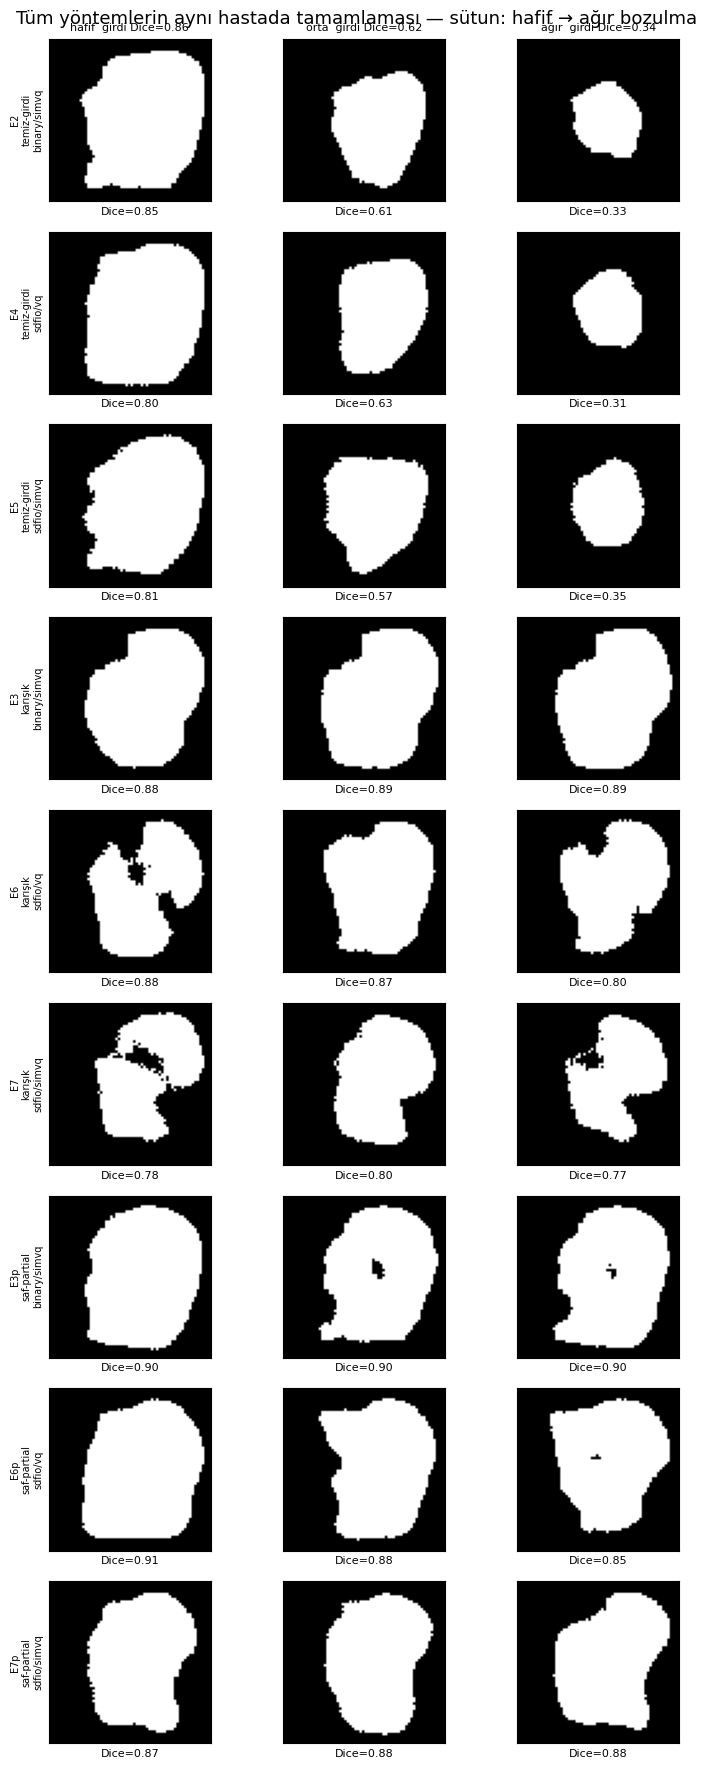

In [13]:
labels = [l for l, *_ in IMG_REGISTRY if l in img_results]
fig, axes = plt.subplots(len(labels), len(panel_broken),
                         figsize=(2.6 * len(panel_broken), 2.0 * len(labels)))
axes = np.atleast_2d(axes)
for ri, lbl in enumerate(labels):
    r = img_results[lbl]; model = r['model']
    for ci, (brk, d_in, lvl) in enumerate(panel_broken):
        comp = complete(model, panel_img, brk)
        d_comp = float(_dc(panel_gt, comp))
        ax = axes[ri, ci]
        ax.imshow(comp[zc], cmap='gray'); ax.set_xticks([]); ax.set_yticks([])
        if ri == 0:
            ax.set_title(f'{lvl.split(chr(10))[0]}  girdi Dice={d_in:.2f}', fontsize=8)
        ax.set_xlabel(f'Dice={d_comp:.2f}', fontsize=8)
        if ci == 0:
            ax.set_ylabel(f'{lbl}\n{r["regime"]}\n{r["head"]}/{r["quantizer"]}', fontsize=7)
fig.suptitle('Tüm yöntemlerin aynı hastada tamamlaması — sütun: hafif → ağır bozulma', fontsize=13)
fig.tight_layout()
out = PROJECT_ROOT / 'outputs' / 'rapor_capraz_karsilastirma.png'
fig.savefig(out, dpi=150, bbox_inches='tight'); print('kaydedildi:', out); plt.show()

## 12. Checkpoint yolundan canlı tek-hasta çıkarımı

Herhangi bir eğitilmiş model, yolu verilerek yeniden yüklenip tek bir test hastası üzerinde
çalıştırılabilir. Aşağıda bir checkpoint yolu, bir hasta indeksi ve bir bozulma hedef-Dice'ı seçilir;
hücre modeli yükler, girdiyi bozar, tamamlamayı üretir ve sonucu gösterir. `CKPT_PATH` /
`PATIENT_IDX` değiştirilerek herhangi bir model/hasta denenebilir.

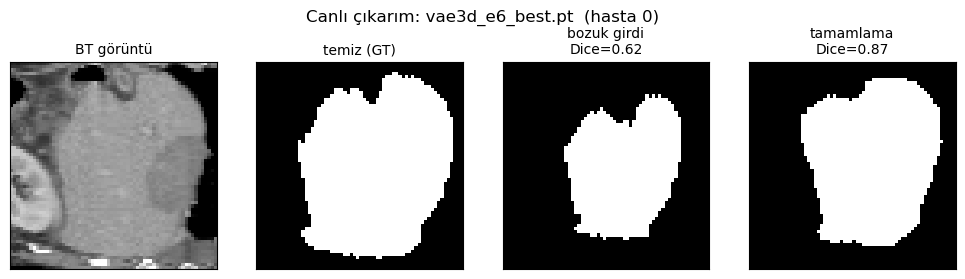

girdi Dice = 0.621  ->  tamamlama Dice = 0.871


In [14]:
CKPT_PATH = CKPT / 'vae3d_e6_best.pt'   # değiştirilebilir
HEAD, QUANT = 'sdfio', 'vq'              # yukarıdaki checkpoint'e uygun olmalı
PATIENT_IDX = 0
TARGET_DICE = 0.6

live_model = evic.load_imgcond_model(CKPT_PATH, HEAD, QUANT, device)
gt = clean_masks[PATIENT_IDX].astype(bool)
img = clean_images[PATIENT_IDX]
rng_live = np.random.default_rng(SEED)
broken, d_in = degrader.make_pair(gt, rng_live, target_dice=TARGET_DICE)
broken = np.asarray(broken) > 0
comp = complete(live_model, img, broken)
from data.degradations import dice as _d
d_comp = float(_d(gt, comp))

zc = gt.shape[0] // 2
titles = ['BT görüntü', 'temiz (GT)', f'bozuk girdi\nDice={d_in:.2f}', f'tamamlama\nDice={d_comp:.2f}']
vols = [img[zc], gt.astype(float)[zc], broken.astype(float)[zc], comp.astype(float)[zc]]
fig, axes = plt.subplots(1, 4, figsize=(10, 2.8))
for ax, t, v in zip(axes, titles, vols):
    ax.imshow(v, cmap='gray'); ax.set_title(t, fontsize=10); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle(f'Canlı çıkarım: {CKPT_PATH.name}  (hasta {PATIENT_IDX})', fontsize=12)
fig.tight_layout(); plt.show()
print(f'girdi Dice = {d_in:.3f}  ->  tamamlama Dice = {d_comp:.3f}')

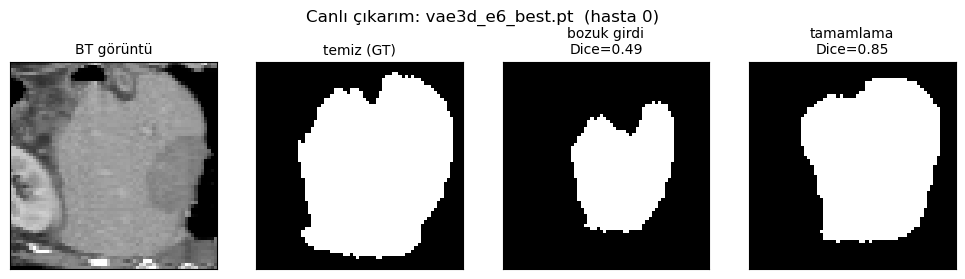

girdi Dice = 0.492  ->  tamamlama Dice = 0.847


In [15]:
CKPT_PATH = CKPT / 'vae3d_e6_best.pt'   # değiştirilebilir
HEAD, QUANT = 'sdfio', 'vq'              # yukarıdaki checkpoint'e uygun olmalı
PATIENT_IDX = 0
TARGET_DICE = 0.3

live_model = evic.load_imgcond_model(CKPT_PATH, HEAD, QUANT, device)
gt = clean_masks[PATIENT_IDX].astype(bool)
img = clean_images[PATIENT_IDX]
rng_live = np.random.default_rng(SEED)
broken, d_in = degrader.make_pair(gt, rng_live, target_dice=TARGET_DICE)
broken = np.asarray(broken) > 0
comp = complete(live_model, img, broken)
from data.degradations import dice as _d
d_comp = float(_d(gt, comp))

zc = gt.shape[0] // 2
titles = ['BT görüntü', 'temiz (GT)', f'bozuk girdi\nDice={d_in:.2f}', f'tamamlama\nDice={d_comp:.2f}']
vols = [img[zc], gt.astype(float)[zc], broken.astype(float)[zc], comp.astype(float)[zc]]
fig, axes = plt.subplots(1, 4, figsize=(10, 2.8))
for ax, t, v in zip(axes, titles, vols):
    ax.imshow(v, cmap='gray'); ax.set_title(t, fontsize=10); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle(f'Canlı çıkarım: {CKPT_PATH.name}  (hasta {PATIENT_IDX})', fontsize=12)
fig.tight_layout(); plt.show()
print(f'girdi Dice = {d_in:.3f}  ->  tamamlama Dice = {d_comp:.3f}')

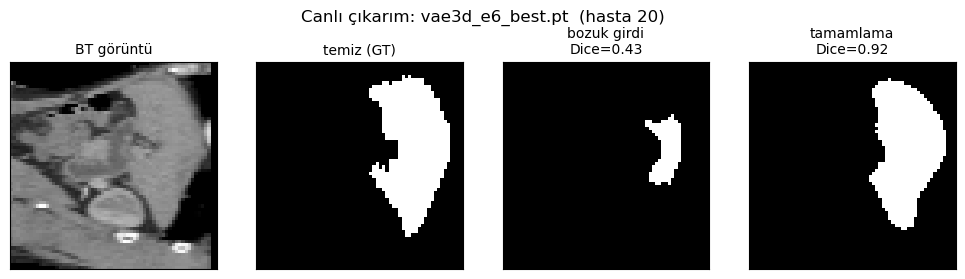

girdi Dice = 0.429  ->  tamamlama Dice = 0.915


In [20]:
CKPT_PATH = CKPT / 'vae3d_e6_best.pt'   # değiştirilebilir
HEAD, QUANT = 'sdfio', 'vq'              # yukarıdaki checkpoint'e uygun olmalı
PATIENT_IDX = 20
TARGET_DICE = 0.2

live_model = evic.load_imgcond_model(CKPT_PATH, HEAD, QUANT, device)
gt = clean_masks[PATIENT_IDX].astype(bool)
img = clean_images[PATIENT_IDX]
rng_live = np.random.default_rng(SEED)
broken, d_in = degrader.make_pair(gt, rng_live, target_dice=TARGET_DICE)
broken = np.asarray(broken) > 0
comp = complete(live_model, img, broken)
from data.degradations import dice as _d
d_comp = float(_d(gt, comp))

zc = gt.shape[0] // 2
titles = ['BT görüntü', 'temiz (GT)', f'bozuk girdi\nDice={d_in:.2f}', f'tamamlama\nDice={d_comp:.2f}']
vols = [img[zc], gt.astype(float)[zc], broken.astype(float)[zc], comp.astype(float)[zc]]
fig, axes = plt.subplots(1, 4, figsize=(10, 2.8))
for ax, t, v in zip(axes, titles, vols):
    ax.imshow(v, cmap='gray'); ax.set_title(t, fontsize=10); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle(f'Canlı çıkarım: {CKPT_PATH.name}  (hasta {PATIENT_IDX})', fontsize=12)
fig.tight_layout(); plt.show()
print(f'girdi Dice = {d_in:.3f}  ->  tamamlama Dice = {d_comp:.3f}')

kullanilabilir bozulmalar: erode, dilate, remove_blob, add_false_positive, boundary_noise, translate, heavy_erode, center_only, partial


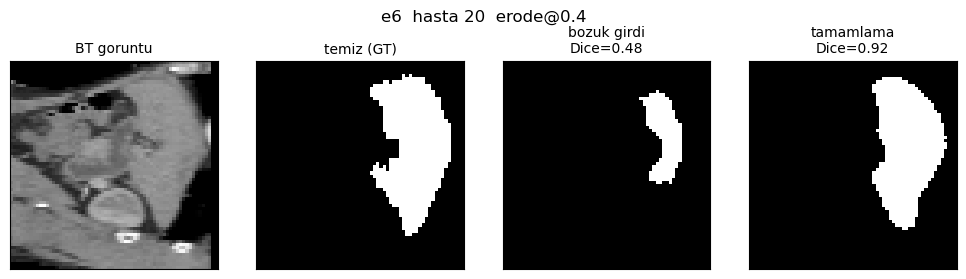

girdi Dice = 0.483  ->  tamamlama Dice = 0.915


In [9]:
# ===================== PARAMETRELER =====================
TAG      = 'e6'            # model: 'e6' (en iyi) | 'e6p' (agir uzman) | 'e3','e7',...
PATIENT  = 20             # 0..46 arasi (test = 47 hasta)
PRIMITIF = 'erode'  # listeden secilebilir: erode, dilate, remove_blob, translate, heavy_erode, center_only, partial
SIDDET   = 0.4            # 0.0–1.0, buyuk = daha cok boz (Dice ~0'a yaklasir)
SEED     = 42             # ayni hastada farkli kirik icin degistir
# ============================================================

import sys
from pathlib import Path
_root = Path.cwd()
for _c in [_root, *_root.parents]:
    if (_c / 'scripts').is_dir() and (_c / 'models').is_dir():
        _root = _c; break
for _p in (_root, _root / 'scripts'):
    if str(_p) not in sys.path:
        sys.path.insert(0, str(_p))

import numpy as np, torch
from data import load_config
from data.degradations import dice as _d
from data.degradations_3d import PRIMITIVES_3D
from data.degradations_partial_3d import PARTIAL_PRIMITIVES_3D
from train import resolve_device
import evaluate_correlation_imgcond as evic
# train/evic importlari matplotlib.use("Agg") cagiriyor -> inline'i SONRA ayarla:
%matplotlib inline
import matplotlib.pyplot as plt

ALL_FNS = {**PRIMITIVES_3D, **PARTIAL_PRIMITIVES_3D}
print('kullanilabilir bozulmalar:', ', '.join(ALL_FNS))

# --- model + hacimleri tembel yukle/onbellekle (parametre degisince yenile) ---
_dev = resolve_device('auto')
if globals().get('_vol_seed') != SEED:
    _cfg = load_config(str(_root / 'configs' / 'vae3d_vq_sdf_io.yaml'))
    _cfg.setdefault('data', {})['data_source'] = 'precomputed'
    _masks, _images = evic.load_clean_image_volumes(_cfg, 'test', None, SEED)
    _vol_seed = SEED
if globals().get('_model_tag') != TAG:
    _HEAD, _QUANT = ('sdfio', 'vq') if ('sdfio' in TAG or TAG.startswith(('e4','e5','e6','e7'))) else ('binary', 'simvq')
    _ckpt = _root / 'outputs' / 'checkpoints' / f'vae3d_{TAG}_best.pt'
    _model = evic.load_imgcond_model(_ckpt, _HEAD, _QUANT, _dev)
    _model_tag = TAG
    print(f'model yuklendi: {_ckpt.name}  (head={_HEAD}, quant={_QUANT})')

# --- sec, boz, tamamla ---
gt  = _masks[PATIENT].astype(bool)
img = _images[PATIENT]
rng = np.random.default_rng(SEED)
broken = np.asarray(ALL_FNS[PRIMITIF](gt, SIDDET, rng)) > 0
d_in = float(_d(gt, broken))

x = torch.from_numpy(np.stack([img, broken.astype('float32')])[None]).float().to(_dev)
with torch.no_grad():
    comp = (_model.reconstruct(x)[0, 0].cpu().numpy() > 0.5)
d_comp = float(_d(gt, comp))

# --- goster (merkez kesit) ---
zc = gt.shape[0] // 2
titles = ['BT goruntu', 'temiz (GT)', f'bozuk girdi\nDice={d_in:.2f}', f'tamamlama\nDice={d_comp:.2f}']
vols   = [img[zc], gt.astype(float)[zc], broken.astype(float)[zc], comp.astype(float)[zc]]
fig, axes = plt.subplots(1, 4, figsize=(10, 2.8))
for ax, t, v in zip(axes, titles, vols):
    ax.imshow(v, cmap='gray'); ax.set_title(t, fontsize=10); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle(f'{TAG}  hasta {PATIENT}  {PRIMITIF}@{SIDDET}', fontsize=12)
fig.tight_layout(); plt.show()
print(f'girdi Dice = {d_in:.3f}  ->  tamamlama Dice = {d_comp:.3f}')

varyant                   d(cikti,GT)  d(cikti,ref)
gercek GT                       0.920         1.000
bos maske                       0.921         0.966
agir bozuk (center_only)        0.918         0.962
yanlis (kaydirilmis)            0.907         0.934


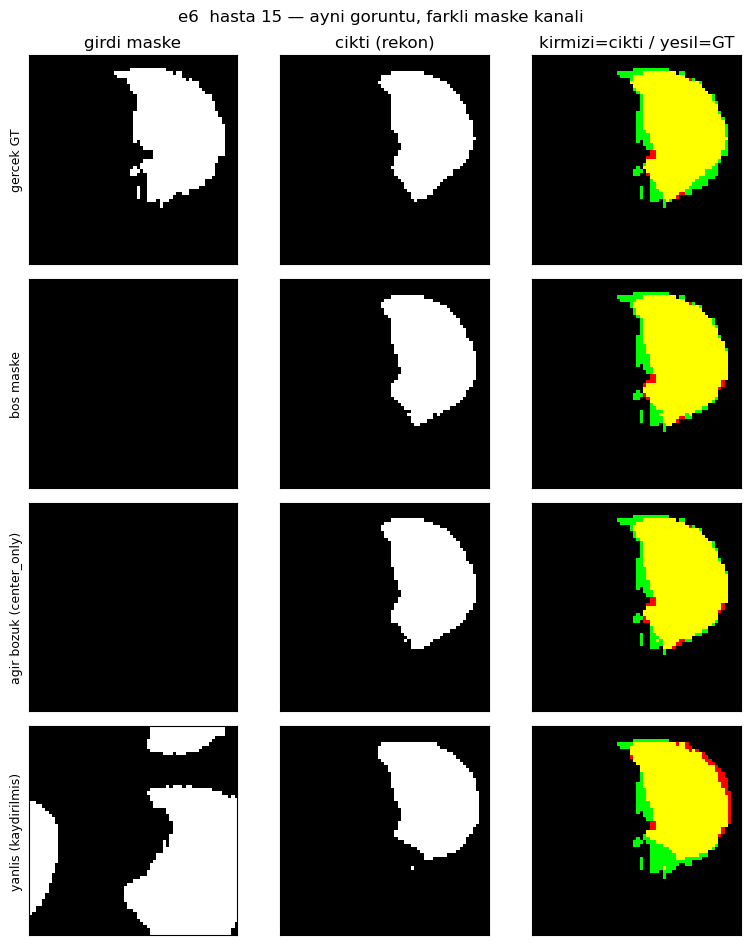


YORUM: d(cikti,ref) sutunu ~1.0 ise maske yok sayiliyor (saf goruntu segmentasyonu);
belirgin dusukse maske hala kullaniliyor.


In [11]:
# ===================== PARAMETRELER =====================
TAG     = 'e6'    # 'e6' | 'e6p' (agir uzman) ; ikisi de sdfio/vq
PATIENT = 15     # 0..46
SEED    = 42
HEAVY   = ('center_only', 0.9)   # agir bozuk varyant icin (primitif, siddet)
SHIFT   = 12     # 'yanlis' varyant: maskeyi kac voksel kaydiralim
# ========================================================

import sys
from pathlib import Path
_root = Path.cwd()
for _c in [_root, *_root.parents]:
    if (_c / 'scripts').is_dir() and (_c / 'models').is_dir():
        _root = _c; break
for _p in (_root, _root / 'scripts'):
    if str(_p) not in sys.path:
        sys.path.insert(0, str(_p))

import numpy as np, torch
from data import load_config
from data.degradations import dice as _d
from data.degradations_3d import PRIMITIVES_3D
from data.degradations_partial_3d import PARTIAL_PRIMITIVES_3D
from train import resolve_device
import evaluate_correlation_imgcond as evic
%matplotlib inline          
# Agg'e zorlayan importlardan SONRA
import matplotlib.pyplot as plt

ALL_FNS = {**PRIMITIVES_3D, **PARTIAL_PRIMITIVES_3D}
_dev = resolve_device('auto')

# model + hacimleri tembel yukle
if globals().get('_vol_seed') != SEED:
    _cfg = load_config(str(_root / 'configs' / 'vae3d_vq_sdf_io.yaml'))
    _cfg.setdefault('data', {})['data_source'] = 'precomputed'
    _masks, _images = evic.load_clean_image_volumes(_cfg, 'test', None, SEED); _vol_seed = SEED
if globals().get('_model_tag') != TAG:
    _ckpt = _root / 'outputs' / 'checkpoints' / f'vae3d_{TAG}_best.pt'
    _model = evic.load_imgcond_model(_ckpt, 'sdfio', 'vq', _dev); _model_tag = TAG
    print('model:', _ckpt.name)

gt  = _masks[PATIENT].astype(bool)
img = _images[PATIENT]
rng = np.random.default_rng(SEED)

# --- 4 maske varyanti (GORUNTU hep ayni) ---
variants = {
    'gercek GT'          : gt.copy(),
    'bos maske'          : np.zeros_like(gt),
    f'agir bozuk ({HEAVY[0]})': np.asarray(ALL_FNS[HEAVY[0]](gt, HEAVY[1], rng)) > 0,
    'yanlis (kaydirilmis)': np.roll(gt, (SHIFT, SHIFT, SHIFT), axis=(0, 1, 2)),
}

@torch.no_grad()
def _recon(mask):
    x = torch.from_numpy(np.stack([img, mask.astype('float32')])[None]).float().to(_dev)
    return (_model.reconstruct(x)[0, 0].cpu().numpy() > 0.5)

recons = {k: _recon(v) for k, v in variants.items()}
ref = recons['gercek GT']   # gercek maskeyle uretilen cikti = referans

zc = gt.shape[0] // 2
fig, axes = plt.subplots(len(variants), 3, figsize=(8, 2.4 * len(variants)))
print(f"{'varyant':24s} {'d(cikti,GT)':>12s} {'d(cikti,ref)':>13s}")
for ri, (name, m) in enumerate(variants.items()):
    r = recons[name]
    d_gt  = _d(gt, r)                 # cikti gercek sekle ne kadar yakin?
    d_ref = _d(ref, r)               # cikti, gercek-maske ciktisina ne kadar benziyor? (~1 => maske onemsiz)
    print(f"{name:24s} {d_gt:12.3f} {d_ref:13.3f}")
    axes[ri, 0].imshow(m[zc], cmap='gray');  axes[ri, 0].set_ylabel(name, fontsize=9)
    axes[ri, 1].imshow(r[zc], cmap='gray')
    ov = np.stack([r[zc].astype(float), gt[zc].astype(float), np.zeros_like(r[zc], float)], -1)
    axes[ri, 2].imshow(ov)
    if ri == 0:
        axes[0, 0].set_title('girdi maske'); axes[0, 1].set_title('cikti (rekon)')
        axes[0, 2].set_title('kirmizi=cikti / yesil=GT')
    for c in range(3): axes[ri, c].set_xticks([]); axes[ri, c].set_yticks([])
fig.suptitle(f'{TAG}  hasta {PATIENT} — ayni goruntu, farkli maske kanali', fontsize=12)
fig.tight_layout(); plt.show()
print("\nYORUM: d(cikti,ref) sutunu ~1.0 ise maske yok sayiliyor (saf goruntu segmentasyonu);")
print("belirgin dusukse maske hala kullaniliyor.")

## 13. Bulguların özeti

- **Tavanı kıran şey tamamlama rejimidir, görüntü kanalının varlığı değil.** Temiz-girdi deneyleri
  (E2/E4/E5) görüntü kanalına rağmen `recon_dice` ρ ≈ 0.82'de, yani maske-only tavanda (~0.83)
  kalır; model temiz maskeyi kopyalayıp görüntüyü yok sayabildiğinden ek bilgi kullanmaz. Girdi
  bozulup model tamamlamaya zorlandığında (karışık ve saf-partial) global ρ 0.94–0.98'e çıkar.

- **Mekanizma.** Bozuk-girdi modeli BT görüntüsünden gerçek organ şeklini kestirmeyi öğrenir;
  `recon_dice` bu tamamlamayı aday maskeyle karşılaştırdığından, skor "adayın gerçek şekle
  uzaklığı"na ≈ gerçek kaliteye yakınsar. Bu, ground-truth gerektirmeyen kalite kestiriminin
  amaçlanan çalışma biçimidir.

- **Karışık vs saf-partial.** İkisi de tavanın belirgin üstünde. Karışık rejim tüm kalite
  yelpazesinde daha dengeli bant-içi ρ verir (genel amaçlı). Saf-partial rejim yalnızca ağır eksik
  maskeler görmesine rağmen yüksek global ρ korur (ağır tamamlamada da çalıştığının kanıtı), ancak
  orta kalite bandında (0.70–0.85) bant-içi ρ'su düşer — bu rejim hafif bozulmaları hiç görmediği
  için oradaki ince farkları daha az ayırt eder. İkisi birlikte yöntemin **çalışma zarfını** verir.

- **Nicemleyici ve baş ikincildir.** Bir rejim içinde VQ↔SimVQ ve binary↔sdfio arasındaki fark
  küçüktür; belirleyici olan girdi rejimidir.

- **`quant_error` kullanılabilir bir sinyal değildir.** Codebook-mesafesi tüm deneylerde gerçek
  kaliteyle zayıf/ilişkisizdir (ρ ≲ 0.37, çoğu ~0). Tek güvenilir kalite skoru `recon_dice`'tır.

- **İstatistiksel çekince.** 282 nokta 47 hastadan gelir; global ρ hastalar-arası varyansla
  şişkindir. Dürüst sayı bant-içi ρ'dur (karışık ≈ 0.6–0.91, saf-partial ≈ 0.25–0.80), bu da
  "güçlü ama mükemmel değil, orta bantta zayıflayan" bir tablo verir.